In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from utils import *

In [2]:
pd.set_option('display.max_columns', None) # display all columns when plotting a dataframe

## Loading the data

In [3]:
dataset = pd.read_csv('datasets/01-dataset.csv', low_memory=False).set_index(['USUBJID', 'VISITNUM'])

In [ ]:
dataset.sort_index().head()

# Table of Contents

##  [1. Feature Engineering](#data_preprocessing)

[1.1. Age Feature Generation](#age)

[1.2. Steroid Medication](#steroid_medication)

[1.3. Mutations](#mutations)

[1.4. Blood Tests](#blood_tests)

[1.5. Functional Tests](#functional_tests)

[1.6. First Signs and Symptoms](#first_symptoms)


## [2. Label Generation](#labels)

[2.1. Uniform representeation of AMBULANT and NON-AMBULANT](#uniform)

[2.2. Exploring the ambulatory state across visits](#amb_state)

[2.3. Creating the labels](#create_labels) 


## [3. Final Dataset-1st Visit](#final_dataset_0)


[3.1. Dealing with Missing Values](#missing_values_0)

[3.2. Dealing with Numerical Features](#numerical_0)

[3.3. Dealing with Categorical Features](#categorical_0)

[3.4. Final Dataset Generation](#final_dataset_generation_0)


## [4. Exploratory Data Analysis](#eda)


# 1. Feature Engineering <a class="anchor" id="data_preprocessing"></a>

## 1.1 Age Feature Generation <a class="anchor" id="age"></a>

Using the dates provided we calculate the following:

* age of DMD diagnosis
* current study
* age entering study
* age leaving study

To calculate the age we only use the **year** of the date and not the month as well.

In [5]:
age_calc = dataset[['MOTOR_STATE_DATE', 'BRTHDTC', 'DMD_DIAGNOSIS', 'DS_ENTERING_STUDY', 'DS_LEAVING_STUDY']]

In [6]:
age_calc = age_calc.replace({'MOTOR_STATE_DATE':{'--': '1000', np.nan: '1000'}})

In [7]:
age_calc['AGE_DIAGNOSIS'] = age_calc.apply(lambda row: 
                                           float(row['DMD_DIAGNOSIS'][0:4]) - float(row['BRTHDTC'][0:4]), axis=1)

age_calc['CURRENT_AGE'] = age_calc.apply(lambda row: 
                                           float(row['MOTOR_STATE_DATE'][0:4]) - float(row['BRTHDTC'][0:4]), axis=1)

age_calc['AGE_ENTERING_STUDY'] = age_calc.apply(lambda row: 
                                                float(row['DS_ENTERING_STUDY'][0:4]) - float(row['BRTHDTC'][0:4]), axis=1)


age_calc['AGE_LEAVING_STUDY'] = age_calc.apply(lambda row: 
                                                float(row['DS_LEAVING_STUDY'][0:4]) - float(row['BRTHDTC'][0:4]), axis=1)

In [ ]:
age_calc

In [9]:
age_calc = age_calc[['AGE_DIAGNOSIS', 'CURRENT_AGE', 'AGE_ENTERING_STUDY', 'AGE_LEAVING_STUDY']] # calculate age

In [10]:
dataset = join_dfs(age_calc, dataset) #add the age to the dataset

In [11]:
dataset = dataset.replace({'CURRENT_AGE':{-1002.: np.nan, -1005.: np.nan, -998.: np.nan,  -995.: np.nan,
                                          -1003.: np.nan, -999.: np.nan,  -997.: np.nan, -1004.: np.nan, 
                                          -1006.: np.nan, -1008.: np.nan}}) # irregular age numbers as unknown

## 1.2. Steroid Medication <a class="anchor" id="steroid_medication"></a>

Refining naming of corticosteroid medication.

In [12]:
dataset = dataset.replace({'STEROID_CM':{'PREDNISOLONE': 'PREDNISONE', 
                                         'HYDROCORTISONE': 'PREDNISONE', 
                                         'METHYLPREDNISOLONE': 'PREDNISONE'}}) 

## 1.3. Mutations <a class="anchor" id="mutations"></a>

In [13]:
dataset = dataset.rename(columns={'DMD_GENE_DELETION': 'MUTATION_LOCATION'})

In [14]:
dataset['MUTATION_LOCATION'].unique()

array(['52-54', '45-52', nan, '51', '17', '62', '45-54', '1-49', '45-50',
       '49-52', '46-47', '-50', '8-16', '20-34', '46-51', '61-74', '54',
       '44', '43', '1-9', '22', '45', '48-52', '3-17', '50', '3-7',
       '53-55', '35-43', '48-50', '8-31', '8-9', '46-53', '49-50',
       '49-54', '10-21', '43-52', '52', '46', '45-56', '46-55', '42-43',
       '46-49', '38-43', '46-48', '33-43', '19', '6-7', '12-18', '5-44',
       '63', '45-62', '1', '4', '3-11', '55', '3-30', '64', '18', '22-34',
       '23', '5-11', '51-55', '15', '51-53', '20', '48-54', '8-26', '-55',
       '47', '46-50', '8-43', '1-45', '33', '53-54', '50-52', '3-29',
       '65', '3-25', '3-13', '63-79', '18-42', '17-43'], dtype=object)

In [15]:
hotspot_mutations = {'52-54', '45-52', '51', '45-54', '1-49', '45-50', 
                     '49-52', '46-47', '-50', '46-51','54', '1-9', '45', 
                     '48-52', '3-17', '50', '3-7', '53-55', '48-50', 
                     '8-9', '46-53', '49-50', '49-54', '43-52', '52', '46', 
                     '45-56', '46-55', '46-49', '46-48', '6-7', '45-62', 
                     '4', '3-11', '55', '3-30', '5-11', '51-55', '51-53', 
                     '48-54', '-55', '47', '46-50', '1-45', '53-54', '50-52', 
                     '3-29', '3-25', '3-13'}

In [16]:
dataset['MUTATION_TYPE'].value_counts()

DELETION             1494
NONSENSE_MUTATION     195
DUPLICATION           150
TRANSLOCATION          16
Name: MUTATION_TYPE, dtype: int64

In [17]:
dataset['HOTSPOT_MUTATION'] = np.where(dataset['MUTATION_LOCATION'].isin(hotspot_mutations), 'YES', 'NO')

In [18]:
dataset.shape

(1855, 202)

## 1.4. Blood Tests <a class="anchor" id="blood_tests"></a>

In [19]:
blood_tests_vars = ['Complement C3c', 
                    'Cystatin C', 
                    'High Sensitivity C-reactive Protein', 
                    'Monocyte Chemotactic Protein 1', 
                    'Albumin', 
                    'Alpha-1 Globulin', 
                    'Cystatine C', 
                    'Kidney Injury Molecule', 
                    'Protein', 
                    'Urine glucose', 'MOTOR_STATE']

In [20]:
dataset = dataset.replace({'Urine glucose':{'<0.1': 0.09}})
dataset = dataset.replace({'High Sensitivity C-reactive Protein':{'<0.3': 0.29}})
dataset = dataset.replace({'Monocyte Chemotactic Protein 1':{'<31.25': 31.25}})
dataset = dataset.replace({'Albumin':{'<3': 2.99, '<12': 11}})
dataset = dataset.replace({'Alpha-1 Globulin':{'<5': 4.99}})
dataset = dataset.replace({'Cystatine C':{'<9130.00': 9129.00, '<20005.00': 20004.00, '>1165560.0': 1165561.0}})
dataset = dataset.replace({'Kidney Injury Molecule':{'<78.20': 78.19}})
dataset = dataset.replace({'Protein':{'<40': 39}})                            

In [21]:
for blood_test in blood_tests_vars[1:-1]:
    dataset[blood_test] = dataset[blood_test].astype(float)

## 1.5. Functional Tests <a class="anchor" id="functional_tests"></a>

#### 1.5.1 4 Stairs Climb Ascending (4SCA)

In [22]:
dataset = dataset.replace({'4-AGRAD':{
    '5= CLIMBS 4 STANDARD STAIRS ALTERNATING FEET, NEEDS HANDRAIL FOR SUPPORT': 5,
    '4= CLIMBS 4 STANDARD STAIRS MARKING TIME (CLIMBS ONE FOOT AT A TIME, WITH BOTH FEET ON A STEP BEFORE MOVING TO NEXT STEP). NOT NEEDING HANDRAIL': 4,
    '6= CLIMBS 4 STANDARD STAIRS ALTERNATING FEET, NOT NEEDING HANDRAIL SUPPORT': 6,
    '3= CLIMBS 4 STANDARD STAIRS MARKING TIME (CLIMBS ONE FOOT AT A TIME, WITH BOTH FEET ON A STEP BEFORE MOVING TO NEXT STEP). USING ONE ARM ON ONE HANDRAIL': 3,
    '2= CLIMBS 4 STANDARD STAIRS MARKING TIME (CLIMBS ONE FOOT AT A TIME, WITH BOTH FEET ON A STEP BEFORE MOVING TO NEXT STEP). USES BOTH ARMS ON ONE OR BOTH HANDRAILS': 2,
    '1= UNABLE TO CLIMB 4 STANDARD STAIRS': 1, 
    np.nan : 0
}})

#### 1.5.2. 4 Stairs Climb Descending (4SCD)

In [23]:
dataset = dataset.replace({'4SCD_4-AGRAD':{
    '4=  DESCENDS 4 STANDARD STAIRS MARKING TIME (DESCENDS 1 FOOT AT A TIME, WITH BOTH FEET ON A STEP BEFORE MOVING TO THE NEXT STEP), NOT NEEDING HANDRAIL': 4,
    '3=  DESCENDS 4 STANDARD STAIRS MARKING TIME (DESCENDS 1 FOOT AT A TIME, WITH BOTH FEET ON A STEP BEFORE MOVING TO THE NEXT STEP), REQUIRES 1 ARM ON A HANDRAIL': 3,
    '5=  DESCENDS 4 STANDARD STAIRS ALTERNATING FEET IN BOTH DIRECTIONS, NEEDS HANDRAIL FOR SUPPORT': 5,
    '2=  DESCENDS 4 STANDARD STAIRS MARKING TIME (DESCENDS 1 FOOT AT A TIME, WITH BOTH FEET ON A STEP BEFORE MOVING TO THE NEXT STEP), REQUIRES BOTH ARMS ON 1 OR BOTH HANDRAILS': 2,
    '6=  DESCENDS 4 STANDARD STAIRS ALTERNATING FEET, NOT NEEDING HANDRAIL SUPPORT': 6,
    '1=  UNABLE TO DESCEND 4 STANDARD STAIRS': 1,
    np.nan : 0
}})

#### 1.5.3. Rise From Floor (RFF)

In [24]:
dataset = dataset.replace({'RISE_FROM_FLOOR':{
    '5= ROLLS TO THE SIDE AND/OR STANDS UP WITH ONE HAND OR BOTH HANDS ON THE FLOOR TO START TO RISE UP BUT DOES NOT TOUCH LEGS': 5,
    '4= HALF GOWERS - ROLLS OVER, STANDS UP WITH ONE HAND SUPPORT ON LEG': 4,
    '3= FULL GOWERS - ROLLS OVER, STANDS UP WITH BOTH HANDS CLIMBING UP THE LEGS TO ACHIEVE FULL UPRIGHT POSTURE': 3,
    '2= ASSISTED GOWERS - REQUIRES FURNITURE FOR ASSIST IN ARISING FROM SUPINE TO FULL UPRIGHT POSTURE': 2,
    '6= STANDS UP WITHOUT ROLLING OVER OR USING HANDS': 6,
    '1= UNABLE TO STAND FROM SUPINE, EVEN WITH USE OF A CHAIR': 1,
    np.nan : 0
}})

#### 1.5.4. 10 Minutes Walk/Run

In [25]:
dataset = dataset.replace({'10MWALK':{
    '6= RUNS AND GETS BOTH FEET OFF THE GROUND (WITH NO DOUBLE STANCE PHASE)': 6,
    '5= ABLE TO PICK UP SPEED, BUT RUNS WITH A DOUBLE STANCE PHASE, I.E., CANNOT ACHIEVE BOTH FEET OFF THE GROUND': 5,
    '4= MODERATELY ADAPTED GAIT. CAN PICK UP SPEED BUT CANNOT RUN': 4,
    '3= HIGHLY ADAPTED WIDE BASED LORDOTIC GAIT. CANNOT INCREASE WALKING SPEED': 3,
    '2= UNABLE TO WALK INDEPENDENTLY, BUT CAN WALK WITH FULL LEG CALIPERS (KAFOS) OR WITH SUPPORT FROM A PERSON': 2,
    np.nan : 0
}})

#### 1.5.5. NSAA (total score)

In [26]:
dataset = dataset.replace({'NSAA':{
    '24/34': 24,
    '26/34': 26,
    '25/34': 25,
    '31/34': 31,
    '32/34': 32,
    '10/34': 10,
    '11/34': 11,
    '12/34': 12,
    '17/34': 17,
    '14/34': 14,
    '4/34': 4,
    '20/34': 20, 
    '19/34': 19, 
    '33/34': 33,
    '28/34': 28, 
    '30/34': 30, 
    '29/34': 29, 
    '22/34': 22, 
    '13/34': 13, 
    '15/34': 15, 
    '18/34': 18,
    '21/34': 21, 
    '27/34': 27, 
    '23/34': 23, 
    '16/34': 16, 
    '7/34': 7, 
    '1/34': 1, 
    '0/34': 0,
    '34/34': 34, 
    '9/34': 9, 
    '8/34': 8, 
    '5/34': 5, 
    '6/34': 6, 
    '3/34': 3, 
    '2/34': 2}})

In [ ]:
dataset['GOWERS_MANOEUVRE']

## 1.6. First Signs and Symptoms <a class="anchor" id="first_symptoms"></a>

In [28]:
age_fss = dataset[['BRTHDTC', 'AMBULATORY_ASSISTANCE', 'LORDOSIS', 'CONTRACTURE', 'GOWERS_MANOEUVRE']]

In [29]:
age_fss['GOWERS_MANOEUVRE'].unique()

array(['2009-04', '2009-03', '2007-06', '2004-06', '2010-11', '2006-01',
       '2008-09', '2009-01', '2009-05', '2010-04', '2011-06', '2012-10',
       '2013-07', '-', '2004-03', '2001-03', '1999-09', '1999-08',
       '2014-04', '2002-06', '2014-10', nan, '2012-01', '2011-11',
       '2011-02', '2013-06', '2015-11', '2013-12', '2013-09', '2013-05',
       '2013-08', '2010-06', '2014-03', '2010-01', '2013-01', '2004-12',
       '2012-06', '2007-11', '2010-12', '2005-01', '2008-01', '2011-12',
       '2008-11', '2009-08', '1998-06', '2004-01', '2011-05', '2010-07',
       '2002-07', '2011-01', '2005-06', '2008-12', '2007-07', '2007-01',
       '2007-08', '2006-08', '2008-07', '2006-06', '2005-04', '2003-09',
       '2003-06', '2012-08', '2008-06', '2012-09', '2003-03', '2006-10',
       '2000-12', '2000-08', '2010-05', '2011-08', '2011-04', '2014-01',
       '2008-02'], dtype=object)

In [30]:
age_fss = age_fss.replace({'AMBULATORY_ASSISTANCE':{'-': '1000', np.nan: '1000'}})
age_fss = age_fss.replace({'LORDOSIS':{'-': '1000', np.nan: '1000'}})
age_fss = age_fss.replace({'CONTRACTURE':{'-': '1000', np.nan: '1000'}})
age_fss = age_fss.replace({'GOWERS_MANOEUVRE':{'-': '1000', np.nan: '1000'}})

In [31]:
age_fss['AGE_AMBULATORY_ASSISTANCE'] = age_fss.apply(lambda row: 
                                           float(row['AMBULATORY_ASSISTANCE'][0:4]) - float(row['BRTHDTC'][0:4]), axis=1)

age_fss['AGE_LORDOSIS'] = age_fss.apply(lambda row: 
                                           float(row['LORDOSIS'][0:4]) - float(row['BRTHDTC'][0:4]), axis=1)

age_fss['AGE_CONTRACTURE'] = age_fss.apply(lambda row: 
                                                float(row['CONTRACTURE'][0:4]) - float(row['BRTHDTC'][0:4]), axis=1)


age_fss['AGE_GOWERS_MANOEUVRE'] = age_fss.apply(lambda row: 
                                                float(row['GOWERS_MANOEUVRE'][0:4]) - float(row['BRTHDTC'][0:4]), axis=1)

In [ ]:
age_fss

In [33]:
# age_calc_static = age_calc.query('VISITNUM == 2')[['AGE_DIAGNOSIS', 'AGE_ENTERING_STUDY', 'AGE_LEAVING_STUDY']]
age_fss = age_fss[['AGE_AMBULATORY_ASSISTANCE', 'AGE_LORDOSIS', 'AGE_CONTRACTURE', 'AGE_GOWERS_MANOEUVRE']]
age_fss.describe()

,AGE_AMBULATORY_ASSISTANCE,AGE_LORDOSIS,AGE_CONTRACTURE,AGE_GOWERS_MANOEUVRE
count,1855.000000,1855.000000,1855.000000,1855.000000
mean,-622.194609,-764.269003,-642.735310,-489.555795
std,490.126420,430.558783,484.781128,504.018845
min,-1010.000000,-1010.000000,-1010.000000,-1010.000000
25%,-1006.000000,-1006.000000,-1006.000000,-1004.000000
50%,-1001.000000,-1003.000000,-1002.000000,1.000000
75%,4.000000,-997.000000,4.000000,4.000000
max,16.000000,19.000000,17.000000,14.000000


In [ ]:
age_fss['AGE_AMBULATORY_ASSISTANCE'] = np.where(age_fss.AGE_AMBULATORY_ASSISTANCE<0, np.nan, age_fss.AGE_AMBULATORY_ASSISTANCE)
age_fss['AGE_LORDOSIS'] = np.where(age_fss.AGE_LORDOSIS<0, np.nan, age_fss.AGE_LORDOSIS)
age_fss['AGE_CONTRACTURE'] = np.where(age_fss.AGE_CONTRACTURE<0, np.nan, age_fss.AGE_CONTRACTURE)
age_fss['AGE_GOWERS_MANOEUVRE'] = np.where(age_fss.AGE_GOWERS_MANOEUVRE<0, np.nan, age_fss.AGE_GOWERS_MANOEUVRE)

In [35]:
age_fss.describe()

,AGE_AMBULATORY_ASSISTANCE,AGE_LORDOSIS,AGE_CONTRACTURE,AGE_GOWERS_MANOEUVRE
count,702.000000,440.000000,663.000000,946.000000
mean,5.759259,7.613636,7.095023,4.367865
std,2.600975,3.637416,3.203806,1.972290
min,2.000000,2.000000,2.000000,1.000000
25%,4.000000,5.000000,4.000000,3.000000
50%,5.000000,7.000000,6.000000,4.000000
75%,7.000000,10.000000,9.000000,5.000000
max,16.000000,19.000000,17.000000,14.000000


In [36]:
dataset = join_dfs(age_fss, dataset)

# 2. Label Generation <a class="anchor" id="labels"></a>

## 2.1. Uniform representation of AMBULANT and NON-AMBULANT class<a class="anchor" id="uniform"></a>

In [37]:
dataset = dataset.replace({'PATIENT GROUP':{'NON AMBULANT':'NON-AMBULANT'}})

In [38]:
dataset.to_csv('datasets/final_dataset.csv')

### Splitting the dataset based on visitnum

In [39]:
dataset = dataset.reset_index()

In [40]:
dataset2 = dataset[dataset['VISITNUM']==2].drop('VISITNUM', axis=1)

dataset3 = dataset[dataset['VISITNUM']==3].drop('VISITNUM', axis=1)

dataset4 = dataset[dataset['VISITNUM']==4].drop('VISITNUM', axis=1)

dataset5 = dataset[dataset['VISITNUM']==5].drop('VISITNUM', axis=1)

dataset6 = dataset[dataset['VISITNUM']==6].drop('VISITNUM', axis=1)

dataset7 = dataset[dataset['VISITNUM']==7].drop('VISITNUM', axis=1)

dataset8 = dataset[dataset['VISITNUM']==8].drop('VISITNUM', axis=1)

## 2.2. Exploring the ambulatory state across visits <a class="anchor" id="amb_state"></a> 

In [41]:
amb_state = {}
for temp in dataset.set_index(['USUBJID','VISITNUM']).groupby('VISITNUM'):
    
    print(f"VISTINUM = {temp[0]}")
    new_temp = temp[1].reset_index('VISITNUM')
    new_temp = new_temp[~new_temp.index.duplicated(keep='first')]
    print(new_temp.MOTOR_STATE.value_counts())
    print(f'Total:{new_temp.MOTOR_STATE.value_counts()[0]+ new_temp.MOTOR_STATE.value_counts()[1]}')
    print('\n')
    amb_state[temp[0]] = new_temp.MOTOR_STATE.value_counts()

VISTINUM = 2
AMBULANT        219
NON-AMBULANT     50
Name: MOTOR_STATE, dtype: int64
Total:269


VISTINUM = 3
AMBULANT        192
NON-AMBULANT     57
Name: MOTOR_STATE, dtype: int64
Total:249


VISTINUM = 4
AMBULANT        178
NON-AMBULANT     64
Name: MOTOR_STATE, dtype: int64
Total:242


VISTINUM = 5
AMBULANT        157
NON-AMBULANT     69
Name: MOTOR_STATE, dtype: int64
Total:226


VISTINUM = 6
AMBULANT        133
NON-AMBULANT     78
Name: MOTOR_STATE, dtype: int64
Total:211


VISTINUM = 7
AMBULANT        88
NON-AMBULANT    47
Name: MOTOR_STATE, dtype: int64
Total:135


VISTINUM = 8
AMBULANT        97
NON-AMBULANT    38
Name: MOTOR_STATE, dtype: int64
Total:135




In [42]:
df = pd.DataFrame(amb_state)
df = df.transpose().reset_index()
df = df.rename(columns={'index':'VISIT'})
df

,VISIT,AMBULANT,NON-AMBULANT
0,2,219,50
1,3,192,57
2,4,178,64
3,5,157,69
4,6,133,78
5,7,88,47
6,8,97,38


In [ ]:
ambulatory_state = dataset.set_index(['USUBJID', 'VISITNUM'])[['MOTOR_STATE', 'MOTOR_STATE_DATE']]
ambulatory_state = ambulatory_state.reset_index('VISITNUM')
ambulatory_state = ambulatory_state.replace({'VISITNUM':{2:'DAY 1',
                                                       3:'MONTH 6', 
                                                       4:'MONTH 12', 
                                                       5:'MONTH 18', 
                                                       6:'MONTH 24', 
                                                       7:'MONTH 30', 
                                                       8:'MONTH 36'}})
ambulatory_state.head()

In [ ]:
ambulatory_state

In [45]:
ambulatory_state = ambulatory_state.groupby('USUBJID').agg(list)

## 2.3. Creating the labels <a class="anchor" id="create_labels"></a> 

First we create a dataset that holds the visitnum, motor state (ambulant, non-ambulant), date of entering and leaving the study and the patient group label.

In [ ]:
labels = dataset.set_index(['USUBJID'])[['VISITNUM','MOTOR_STATE','MOTOR_STATE_DATE', 'DS_ENTERING_STUDY', 'DS_LEAVING_STUDY', 'PATIENT GROUP']]
labels

In [48]:
# We hold the non-ambulant subject indexes at the beginning of the study in order to remove them 
# from the final dataset

non_ambulant_indexes = labels[labels.VISITNUM==2]
non_ambulant_indexes = non_ambulant_indexes[non_ambulant_indexes.MOTOR_STATE=='NON-AMBULANT'].index
# non_ambulant_indexes

In [49]:
labels = labels.drop(index=non_ambulant_indexes)
print(labels.shape)

(7430, 6)


In [50]:
labels = labels.reset_index().drop_duplicates()
print(labels.shape)

(1221, 7)


In [51]:
labels['MOTOR_STATE'] = np.where(labels.MOTOR_STATE.isna(), 'UNKOWN', labels.MOTOR_STATE)

In [ ]:
labels

In [53]:
labels = labels.reset_index().drop_duplicates()
print(labels.shape)
labels['MOTOR_STATE_DATE'] = np.where(labels.MOTOR_STATE_DATE=='--', np.nan, labels.MOTOR_STATE_DATE)
labels = labels.dropna(subset=['MOTOR_STATE', 'MOTOR_STATE_DATE', 'DS_ENTERING_STUDY', 'DS_LEAVING_STUDY'])
print(labels.shape)

labels = labels.set_index('USUBJID')

(1221, 8)
(1211, 8)


In [54]:
msd_visitnum_2 = (
    labels[labels.VISITNUM==2][['MOTOR_STATE_DATE']]
        .rename(columns={'MOTOR_STATE_DATE': 'MSD_VISITNUM_2'})
)

labels = labels.join(msd_visitnum_2, on='USUBJID')

In [56]:
# MOTOR_STATE_DATE-DS_ENTERING_STUDY
labels['MSDATE-ESDATE'] = pd.to_datetime(labels.MOTOR_STATE_DATE, format="%Y-%m-%d")\
-pd.to_datetime(labels.MSD_VISITNUM_2, format="%Y-%m-%d")

In [ ]:
labels.sort_values(by=['USUBJID', 'VISITNUM'])

## Creating the ambulant-to-non-ambulant labels

In [59]:
# we choose only those that become non-ambulant
ambulant_to_non_ambulant_labels = labels[labels.MOTOR_STATE=='NON-AMBULANT'] 

# we hold the first time they become non-ambulant
ambulant_to_non_ambulant_labels = ambulant_to_non_ambulant_labels.groupby('USUBJID').agg({'MSDATE-ESDATE':min})

# we create the event label (meaning that they experienced the event)
ambulant_to_non_ambulant_labels['EVENT'] = "True"

# we hold the indexes of the subject that become non-ambulant
ambulant_to_non_amb_subjects = ambulant_to_non_ambulant_labels.index.to_list()

# we rename the 'MSDATE-ESDATE' column to time 
ambulant_to_non_ambulant_labels = ambulant_to_non_ambulant_labels.rename(columns={'MSDATE-ESDATE': 'TIME'})

## Creating the ambulant labels

In [60]:
# we choose only the subjects that remain ambulant by removing the amb-to-non-amb subjects
ambulant_labels = labels.drop(index=ambulant_to_non_amb_subjects)

# we hold the last time the subject was last labeled as ambulant
ambulant_labels = ambulant_labels.groupby('USUBJID').agg({'MSDATE-ESDATE':max})

# we create the event label (meaning that they did not experience the event)
ambulant_labels['EVENT'] = "False"

# we hold the indexes of the subject that become non-ambulant
ambulant_subjects = ambulant_labels.index.to_list()

# we rename the 'MSDATE-ESDATE' column to time 
ambulant_labels = ambulant_labels.rename(columns={'MSDATE-ESDATE': 'TIME'})

## Final Labels

In [61]:
# First we concatenate the two created labels datasets
final_labels = pd.concat([ambulant_labels, ambulant_to_non_ambulant_labels])

In [62]:
final_labels.shape

(219, 2)

# 3. Final Dataset-1st Visit  <a class="anchor" id="final_dataset_0"></a> 

Adding the created labels to the dataset

In [63]:
final_df = dataset2.set_index('USUBJID')\
            .drop(index=non_ambulant_indexes)\
            .reset_index()\
            .drop_duplicates(subset='USUBJID')\
            .set_index('USUBJID')

In [64]:
final_df = final_df.join(final_labels, on='USUBJID', how='outer')

## 3.1. Missing Values Overview <a class="anchor" id="missing_values_0"></a> 

It should be considered that some features refer only to **ambulant** and some others only to **non-ambulant patients**.


In [66]:
columns_ = ['IL_HISTORY', 
            'PATIENT GROUP', 
            'STEROIDS', 
            'STARTING POINT FOR SUBSEQUENT TESTS', 
            'EGABSP', 
            'QSTOTS',
            'MOTOR_STATE', 'WALK75M', 'MOTOR_STATE_DATE', 
            'DSTERM', 'DS_ENTERING_STUDY', 'DS_LEAVING_STUDY',
            'BRTHDTC',
            'DMTECH',
            'DMD_DIAGNOSIS',
            'MHINTOTH', 'MH', 
            'HO',
            'PREVIOUS_STEROID_USE', 'PUSSGDTC', 'OTHER_CM', 'CARDIAC_MEDICATION',
            'AGE_ENTERING_STUDY',
            'AGE_LEAVING_STUDY', 
            'AMBULATORY_ASSISTANCE', 'LORDOSIS', 'GOWERS_MANOEUVRE', 'CONTRACTURE'
           ]

In [67]:
final_df = final_df.drop(columns=columns_)

Plot the percentage of missing values for each feature.



In [68]:
missing_df = missing_values(final_df)\
    .transpose()\
    .reset_index()\
    .rename(columns={'index':'feature'})\
    .sort_values(by='Percent(%)')


plt.figure(figsize=(20, 150))
sns.set(font_scale=1)
sns.barplot(x = missing_df['Percent(%)'], y = missing_df.feature, data=missing_df)
plt.show()

As expected since some features refer to non-ambulant subjects that have been excluded from the dataset, there are a few features with 100% missing values. There are also a lot of features that have 20-80% missing values.


First, we drop the columns that have more than 80% missing values.

In [69]:
df = drop_missing_values(final_df, 80)

df.shape

(219, 154)

In [70]:
missing_values(df)

,Complement C3c,Cystatin C,High Sensitivity C-reactive Protein,Monocyte Chemotactic Protein 1,Albumin,Alpha-1 Globulin,Cystatine C,Kidney Injury Molecule,Protein,Urine glucose,3 POINT GRIP,FINGER PINCH GRIP,PICKING UP COINS,PLACING FINGER ON NUMBER DIAGRAM,PUSH ON THE LIGHT,SUPINATION,THUMB (KEY) GRIP,TRACING PATH,SHOULDER ABDUCTION TO SHOULDER HEIGHT,SHOULDER ABDUCTION ABOVE SHOULDER HEIGHT,SHOULDER FLEXION TO SHOULDER HEIGHT,SHOULDER FLEXION ABOVE SHOULDER HEIGHT,HAND(S) TO TABLE FROM LAP,HAND(S) TO MOUTH,LIFTING HEAVY CANS,LIFTING LIGHT CANS,MOVE WEIGHT ON TABLE,REMOVE LID FROM CONTAINER,STACKING HEAVY CANS,STACKING LIGHT CANS,TEARING PAPER,PREFERRED ARM,ELBOW CONTRACTURES,SPINAL SURGERY,ECGRES,PR,QRS,QT,QTc,NSAA,CLIMB BOX STEP - LEFT,CLIMB BOX STEP - RIGHT,DESCEND BOX STEP - LEFT,DESCEND BOX STEP - RIGHT,GETS TO SITTING,HOP LEFT LEG,HOP RIGHT LEG,JUMP,LIFTS HEAD,RISE FROM FLOOR,RUN(10M),STAND,STAND UP FROM CHAIR,STANDS ON HEELS,STAND ON ONE LEG - LEFT,STAND ON ONE LEG - RIGHT,WALK,BMMODEL,BONE MINERAL CONTENT,WHOLE BODY FAT TISSUE MASS,WHOLE BODY LEAN TISSUE MASS,FRACTIONAL SHORTENING,LEFT POSTERIOR WALL THICKNESS,LEFT SEPTUM WALL THICKNESS,LV END DIASTOLIC DIAMETER,LVEF,LV END SYSTOLIC DIAMETER,LEFT ANKLE DORSIFLEXION (SITTING),RIGHT ANKLE DORSIFLEXION (SITTING),ELBOW EXTENSION(LEFT),ELBOW EXTENSION (RIGHT),LEFT HIP EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),RIGHT HIP EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),LEFT ILIO TIBIAL BANDS (SUPINE-AMBULANT PATIENTS ONLY),RIGHT ILIO TIBIAL BANDS (SUPINE-AMBULANT PATIENTS ONLY),LEFT KNEE EXTENSION (SITTING),RIGHT KNEE EXTENSION (SITTING),SHOULDER FLEXION (LEFT),SHOULDER FLEXION (RIGHT),WRIST EXTENSION (LEFT),WRIST EXTENSION (RIGHT),ELBOW EXTENSOR,ELBOW FLEXOR,KNEE EXTENSOR,SHOULDER FLEXOR,SUPINE ELBOW EXTENSOR,SUPINE ELBOW FLEXOR,WRIST EXTENSOR,LEFT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY),RIGHT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY),LEFT KNEE EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),RIGHT KNEE EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),ABDOM,CARDSYS,EAR,EYES,HAIR,LYNDS,MNTST,MUSSYS,NURSYS,RESSYS,SKIN,THROAT,6MWD_AIDS,6MWD_SHOES,6MWD_DISWLK,6MWD_NOFALL,10MWALK,10MWR_AIDS,10MWR_SHOES,4SCA_4-AGRAD,4SCA_AIDS,4SCA_SHOES,4SCD_4-AGRAD,4SCD_AIDS,4SCD_SHOES,RISE_FROM_FLOOR,FEV1,FEV1%,FVC,FVC%,MEP,MIP,PCF,PF,PF%,BMI,DIASBP,HEIGHT,HR,RR,SYSBP,WEIGHT,RACE,ETHNIC,MHINT,MUTATION_TYPE,PRESENT_STEROID_USE,PAST_STEROID_USE,MUTATION_LOCATION,STEROID_CM,STEROID_DOSE,STEROID_FRQ,OSTEOPOROSIS_PREVENTION,AGE_DIAGNOSIS,CURRENT_AGE,HOTSPOT_MUTATION,AGE_AMBULATORY_ASSISTANCE,AGE_LORDOSIS,AGE_CONTRACTURE,AGE_GOWERS_MANOEUVRE,TIME,EVENT
Total,15,15,14,20,9,10,50,10,9,9,73,73,71,73,71,71,74,71,72,73,72,72,71,71,76,76,71,70,76,76,70,74,70,71,88,92,90,91,91,4,1,1,2,1,1,1,1,1,1,2,3,0,1,1,1,1,0,128,128,140,140,111,123,124,106,121,118,11,11,6,6,8,8,9,9,10,10,7,6,6,5,15,15,18,17,76,96,18,8,8,8,8,0,0,0,13,0,1,1,0,2,0,0,0,18,17,16,16,0,5,5,15,17,16,0,19,18,0,50,63,42,53,114,121,118,60,101,2,11,3,4,45,11,2,0,0,0,0,0,0,44,17,17,17,13,0,0,0,144,172,162,130,0,0
Percent(%),6.849315,6.849315,6.392694,9.13242,4.109589,4.56621,22.83105,4.56621,4.109589,4.109589,33.333333,33.333333,32.420091,33.333333,32.420091,32.420091,33.789954,32.420091,32.876712,33.333333,32.876712,32.876712,32.420091,32.420091,34.703196,34.703196,32.420091,31.96347,34.703196,34.703196,31.96347,33.789954,31.96347,32.420091,40.182648,42.009132,41.09589,41.552511,41.552511,1.826484,0.456621,0.456621,0.913242,0.456621,0.456621,0.456621,0.456621,0.456621,0.456621,0.913242,1.369863,0.0,0.456621,0.456621,0.456621,0.456621,0.0,58.447489,58.447489,63.926941,63.926941,50.684932,56.164384,56.621005,48.401826,55.251142,53.881279,5.022831,5.022831,2.739726,2.739726,3.652968,3.652968,4.109589,4.109589,4.56621,4.56621,3.196347,2.739726,2.739726,2.283105,6.849315,6.849315,8.219178,7.762557,34.703196,43.835616,8.219178,3.652968,3.652968,3.652968,3.652968,0.0,0.0,0.0,5.936073,0.0,0.456621,0.456621,0.0,0.913242,0.0,0.0,0.0,8.219178,7.762557,7.305936,

#### Some final touches

In [71]:
df['TIME_IN_DAYS'] =\
df['TIME'].astype(str).str.replace('\sdays', '', regex=True).astype(int)

In [72]:
df = df.drop(columns='TIME', axis=1)



In [73]:
missing_df = missing_values(df)\
    .transpose()\
    .reset_index()\
    .rename(columns={'index':'feature'})\
    .sort_values(by='Percent(%)')


plt.figure(figsize=(20, 150))
sns.set(font_scale=1)
sns.barplot(x = missing_df['Percent(%)'], y = missing_df.feature, data=missing_df)
plt.show()

In [74]:
df.shape

(219, 154)

## Check missing values per instance

In [75]:
missing_values(df.transpose())

USUBJID,PRO-DMD-01-0101,PRO-DMD-01-0102,PRO-DMD-01-0103,PRO-DMD-01-0104,PRO-DMD-01-0105,PRO-DMD-01-0106,PRO-DMD-01-0107,PRO-DMD-01-0108,PRO-DMD-01-0109,PRO-DMD-01-0110,PRO-DMD-01-0111,PRO-DMD-01-0112,PRO-DMD-01-0113,PRO-DMD-01-0114,PRO-DMD-01-0119,PRO-DMD-01-0121,PRO-DMD-01-0122,PRO-DMD-01-0201,PRO-DMD-01-0202,PRO-DMD-01-0203,PRO-DMD-01-0204,PRO-DMD-01-0205,PRO-DMD-01-0206,PRO-DMD-01-0207,PRO-DMD-01-0208,PRO-DMD-01-0209,PRO-DMD-01-0301,PRO-DMD-01-0302,PRO-DMD-01-0304,PRO-DMD-01-0305,PRO-DMD-01-0306,PRO-DMD-01-0307,PRO-DMD-01-0308,PRO-DMD-01-0309,PRO-DMD-01-0310,PRO-DMD-01-0311,PRO-DMD-01-0401,PRO-DMD-01-0402,PRO-DMD-01-0405,PRO-DMD-01-0407,PRO-DMD-01-0408,PRO-DMD-01-0410,PRO-DMD-01-0411,PRO-DMD-01-0413,PRO-DMD-01-0414,PRO-DMD-01-0416,PRO-DMD-01-0417,PRO-DMD-01-0501,PRO-DMD-01-0503,PRO-DMD-01-0504,PRO-DMD-01-0505,PRO-DMD-01-0506,PRO-DMD-01-0507,PRO-DMD-01-0508,PRO-DMD-01-0603,PRO-DMD-01-0605,PRO-DMD-01-0703,PRO-DMD-01-0705,PRO-DMD-01-0801,PRO-DMD-01-0802,PRO-DMD-01-0803,PRO-DMD-01-0804,PRO-DMD-01-0805,PRO-DMD-01-0806,PRO-DMD-01-0807,PRO-DMD-01-0808,PRO-DMD-01-0809,PRO-DMD-01-0810,PRO-DMD-01-0811,PRO-DMD-01-0812,PRO-DMD-01-0813,PRO-DMD-01-0814,PRO-DMD-01-0815,PRO-DMD-01-0816,PRO-DMD-01-0817,PRO-DMD-01-0818,PRO-DMD-01-0819,PRO-DMD-01-0820,PRO-DMD-01-0821,PRO-DMD-01-0822,PRO-DMD-01-0823,PRO-DMD-01-0824,PRO-DMD-01-0825,PRO-DMD-01-0826,PRO-DMD-01-0827,PRO-DMD-01-0828,PRO-DMD-01-0829,PRO-DMD-01-0831,PRO-DMD-01-0833,PRO-DMD-01-0834,PRO-DMD-01-0835,PRO-DMD-01-0836,PRO-DMD-01-0837,PRO-DMD-01-0838,PRO-DMD-01-0839,PRO-DMD-01-0841,PRO-DMD-01-0843,PRO-DMD-01-0844,PRO-DMD-01-0849,PRO-DMD-01-0851,PRO-DMD-01-0901,PRO-DMD-01-0902,PRO-DMD-01-0903,PRO-DMD-01-0904,PRO-DMD-01-0905,PRO-DMD-01-0906,PRO-DMD-01-0907,PRO-DMD-01-0908,PRO-DMD-01-0909,PRO-DMD-01-0910,PRO-DMD-01-0911,PRO-DMD-01-0912,PRO-DMD-01-0913,PRO-DMD-01-0914,PRO-DMD-01-0915,PRO-DMD-01-0916,PRO-DMD-01-0917,PRO-DMD-01-0918,PRO-DMD-01-0919,PRO-DMD-01-0920,PRO-DMD-01-0921,PRO-DMD-01-0922,PRO-DMD-01-0923,PRO-DMD-01-0924,PRO-DMD-01-0925,PRO-DMD-01-0926,PRO-DMD-01-0927,PRO-DMD-01-0928,PRO-DMD-01-0929,PRO-DMD-01-0930,PRO-DMD-01-0931,PRO-DMD-01-0932,PRO-DMD-01-0933,PRO-DMD-01-0934,PRO-DMD-01-0935,PRO-DMD-01-0936,PRO-DMD-01-0937,PRO-DMD-01-0938,PRO-DMD-01-0939,PRO-DMD-01-0940,PRO-DMD-01-1003,PRO-DMD-01-1004,PRO-DMD-01-1005,PRO-DMD-01-1006,PRO-DMD-01-1007,PRO-DMD-01-1101,PRO-DMD-01-1102,PRO-DMD-01-1103,PRO-DMD-01-1104,PRO-DMD-01-1105,PRO-DMD-01-1106,PRO-DMD-01-1107,PRO-DMD-01-1108,PRO-DMD-01-1109,PRO-DMD-01-1110,PRO-DMD-01-1111,PRO-DMD-01-1112,PRO-DMD-01-1113,PRO-DMD-01-1114,PRO-DMD-01-1201,PRO-DMD-01-1202,PRO-DMD-01-1203,PRO-DMD-01-1204,PRO-DMD-01-1206,PRO-DMD-01-1207,PRO-DMD-01-1208,PRO-DMD-01-1301,PRO-DMD-01-1302,PRO-DMD-01-1303,PRO-DMD-01-1304,PRO-DMD-01-1305,PRO-DMD-01-1306,PRO-DMD-01-1307,PRO-DMD-01-1308,PRO-DMD-01-1310,PRO-DMD-01-1311,PRO-DMD-01-1312,PRO-DMD-01-1313,PRO-DMD-01-1314,PRO-DMD-01-1315,PRO-DMD-01-1316,PRO-DMD-01-1317,PRO-DMD-01-1318,PRO-DMD-01-1319,PRO-DMD-01-1320,PRO-DMD-01-1321,PRO-DMD-01-1322,PRO-DMD-01-1323,PRO-DMD-01-1401,PRO-DMD-01-1402,PRO-DMD-01-1403,PRO-DMD-01-1404,PRO-DMD-01-1407,PRO-DMD-01-1408,PRO-DMD-01-1409,PRO-DMD-01-1411,PRO-DMD-01-1412,PRO-DMD-01-1413,PRO-DMD-01-1414,PRO-DMD-01-1415,PRO-DMD-01-1416,PRO-DMD-01-1502,PRO-DMD-01-1503,PRO-DMD-01-1505,PRO-DMD-01-1506,PRO-DMD-01-1507,PRO-DMD-01-1508,PRO-DMD-01-1509,PRO-DMD-01-1510,PRO-DMD-01-1601,PRO-DMD-01-1603,PRO-DMD-01-1605,PRO-DMD-01-1606,PRO-DMD-01-0840,PRO-DMD-01-1001,PRO-DMD-01-1002,PRO-DMD-01-1210,PRO-DMD-01-1604,PRO-DMD-01-0601
Total,33,33,31,29,28,29,28,30,29,30,39,25,43,21,3,37,37,30,30,29,65,37,35,42,33,18,45,54,46,49,62,50,17,25,43,17,48,40,56,47,39,17,12,17,18,32,19,12,5,6,12,20,20,14,20,11,32,15,34,35,32,33,36,28,29,34,28,36,34,28,33,38,29,30,34,8,12,15,12,4,9,11,3,13,1,2,9,2,3,5,19,76,2,18,12,7,27,21,14,15,14,24,19,19,20,20,19,19,19,20,22,19,22,23,24,28,26,23,22,23,22,25,24,23,37,23,23,25,23,23,23,23,24,23,24,23,25,17,17,28,46,70,37,35,20,39,43,54,54,46,48,64,44,17,23,30,19,20,22,40,47,39,46,26,27,32

## Check missing values of features only for the subjects that become non-ambulant

In [76]:
missing_values(df[df['EVENT']=='True'])

,Complement C3c,Cystatin C,High Sensitivity C-reactive Protein,Monocyte Chemotactic Protein 1,Albumin,Alpha-1 Globulin,Cystatine C,Kidney Injury Molecule,Protein,Urine glucose,3 POINT GRIP,FINGER PINCH GRIP,PICKING UP COINS,PLACING FINGER ON NUMBER DIAGRAM,PUSH ON THE LIGHT,SUPINATION,THUMB (KEY) GRIP,TRACING PATH,SHOULDER ABDUCTION TO SHOULDER HEIGHT,SHOULDER ABDUCTION ABOVE SHOULDER HEIGHT,SHOULDER FLEXION TO SHOULDER HEIGHT,SHOULDER FLEXION ABOVE SHOULDER HEIGHT,HAND(S) TO TABLE FROM LAP,HAND(S) TO MOUTH,LIFTING HEAVY CANS,LIFTING LIGHT CANS,MOVE WEIGHT ON TABLE,REMOVE LID FROM CONTAINER,STACKING HEAVY CANS,STACKING LIGHT CANS,TEARING PAPER,PREFERRED ARM,ELBOW CONTRACTURES,SPINAL SURGERY,ECGRES,PR,QRS,QT,QTc,NSAA,CLIMB BOX STEP - LEFT,CLIMB BOX STEP - RIGHT,DESCEND BOX STEP - LEFT,DESCEND BOX STEP - RIGHT,GETS TO SITTING,HOP LEFT LEG,HOP RIGHT LEG,JUMP,LIFTS HEAD,RISE FROM FLOOR,RUN(10M),STAND,STAND UP FROM CHAIR,STANDS ON HEELS,STAND ON ONE LEG - LEFT,STAND ON ONE LEG - RIGHT,WALK,BMMODEL,BONE MINERAL CONTENT,WHOLE BODY FAT TISSUE MASS,WHOLE BODY LEAN TISSUE MASS,FRACTIONAL SHORTENING,LEFT POSTERIOR WALL THICKNESS,LEFT SEPTUM WALL THICKNESS,LV END DIASTOLIC DIAMETER,LVEF,LV END SYSTOLIC DIAMETER,LEFT ANKLE DORSIFLEXION (SITTING),RIGHT ANKLE DORSIFLEXION (SITTING),ELBOW EXTENSION(LEFT),ELBOW EXTENSION (RIGHT),LEFT HIP EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),RIGHT HIP EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),LEFT ILIO TIBIAL BANDS (SUPINE-AMBULANT PATIENTS ONLY),RIGHT ILIO TIBIAL BANDS (SUPINE-AMBULANT PATIENTS ONLY),LEFT KNEE EXTENSION (SITTING),RIGHT KNEE EXTENSION (SITTING),SHOULDER FLEXION (LEFT),SHOULDER FLEXION (RIGHT),WRIST EXTENSION (LEFT),WRIST EXTENSION (RIGHT),ELBOW EXTENSOR,ELBOW FLEXOR,KNEE EXTENSOR,SHOULDER FLEXOR,SUPINE ELBOW EXTENSOR,SUPINE ELBOW FLEXOR,WRIST EXTENSOR,LEFT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY),RIGHT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY),LEFT KNEE EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),RIGHT KNEE EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),ABDOM,CARDSYS,EAR,EYES,HAIR,LYNDS,MNTST,MUSSYS,NURSYS,RESSYS,SKIN,THROAT,6MWD_AIDS,6MWD_SHOES,6MWD_DISWLK,6MWD_NOFALL,10MWALK,10MWR_AIDS,10MWR_SHOES,4SCA_4-AGRAD,4SCA_AIDS,4SCA_SHOES,4SCD_4-AGRAD,4SCD_AIDS,4SCD_SHOES,RISE_FROM_FLOOR,FEV1,FEV1%,FVC,FVC%,MEP,MIP,PCF,PF,PF%,BMI,DIASBP,HEIGHT,HR,RR,SYSBP,WEIGHT,RACE,ETHNIC,MHINT,MUTATION_TYPE,PRESENT_STEROID_USE,PAST_STEROID_USE,MUTATION_LOCATION,STEROID_CM,STEROID_DOSE,STEROID_FRQ,OSTEOPOROSIS_PREVENTION,AGE_DIAGNOSIS,CURRENT_AGE,HOTSPOT_MUTATION,AGE_AMBULATORY_ASSISTANCE,AGE_LORDOSIS,AGE_CONTRACTURE,AGE_GOWERS_MANOEUVRE,EVENT,TIME_IN_DAYS
Total,6,6,5,7,4,4,11,4,4,4,10,10,10,10,10,10,10,10,11,12,11,11,10,10,11,11,10,9,11,11,9,11,9,10,27,27,27,28,28,2,1,1,1,1,0,0,0,0,0,1,2,0,0,0,0,0,0,34,34,37,37,36,37,38,34,37,36,0,0,0,0,1,1,2,2,0,0,0,0,0,0,2,2,4,2,11,17,2,1,1,1,1,0,0,0,2,0,0,0,0,0,0,0,0,5,5,4,4,0,3,3,11,12,12,0,13,13,0,7,11,5,8,30,30,30,11,25,0,1,1,0,12,1,1,0,0,0,0,0,0,11,6,6,6,2,0,0,0,38,40,39,37,0,0
Percent(%),11.538462,11.538462,9.615385,13.461538,7.692308,7.692308,21.153846,7.692308,7.692308,7.692308,19.230769,19.230769,19.230769,19.230769,19.230769,19.230769,19.230769,19.230769,21.153846,23.076923,21.153846,21.153846,19.230769,19.230769,21.153846,21.153846,19.230769,17.307692,21.153846,21.153846,17.307692,21.153846,17.307692,19.230769,51.923077,51.923077,51.923077,53.846154,53.846154,3.846154,1.923077,1.923077,1.923077,1.923077,0.0,0.0,0.0,0.0,0.0,1.923077,3.846154,0.0,0.0,0.0,0.0,0.0,0.0,65.384615,65.384615,71.153846,71.153846,69.230769,71.153846,73.076923,65.384615,71.153846,69.230769,0.0,0.0,0.0,0.0,1.923077,1.923077,3.846154,3.846154,0.0,0.0,0.0,0.0,0.0,0.0,3.846154,3.846154,7.692308,3.846154,21.153846,32.692308,3.846154,1.923077,1.923077,1.923077,1.923077,0.0,0.0,0.0,3.846154,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.615385,9.615385,7.692308,7.692308,0.0,5.769231,5.769231,21.153846,23.076923,23.076923,0.0,25.0,25.0,0.0,13.461538,21.153846,9.615385,15.384615,57.692308,57.692308,5

In [77]:
missing_values(df)

,Complement C3c,Cystatin C,High Sensitivity C-reactive Protein,Monocyte Chemotactic Protein 1,Albumin,Alpha-1 Globulin,Cystatine C,Kidney Injury Molecule,Protein,Urine glucose,3 POINT GRIP,FINGER PINCH GRIP,PICKING UP COINS,PLACING FINGER ON NUMBER DIAGRAM,PUSH ON THE LIGHT,SUPINATION,THUMB (KEY) GRIP,TRACING PATH,SHOULDER ABDUCTION TO SHOULDER HEIGHT,SHOULDER ABDUCTION ABOVE SHOULDER HEIGHT,SHOULDER FLEXION TO SHOULDER HEIGHT,SHOULDER FLEXION ABOVE SHOULDER HEIGHT,HAND(S) TO TABLE FROM LAP,HAND(S) TO MOUTH,LIFTING HEAVY CANS,LIFTING LIGHT CANS,MOVE WEIGHT ON TABLE,REMOVE LID FROM CONTAINER,STACKING HEAVY CANS,STACKING LIGHT CANS,TEARING PAPER,PREFERRED ARM,ELBOW CONTRACTURES,SPINAL SURGERY,ECGRES,PR,QRS,QT,QTc,NSAA,CLIMB BOX STEP - LEFT,CLIMB BOX STEP - RIGHT,DESCEND BOX STEP - LEFT,DESCEND BOX STEP - RIGHT,GETS TO SITTING,HOP LEFT LEG,HOP RIGHT LEG,JUMP,LIFTS HEAD,RISE FROM FLOOR,RUN(10M),STAND,STAND UP FROM CHAIR,STANDS ON HEELS,STAND ON ONE LEG - LEFT,STAND ON ONE LEG - RIGHT,WALK,BMMODEL,BONE MINERAL CONTENT,WHOLE BODY FAT TISSUE MASS,WHOLE BODY LEAN TISSUE MASS,FRACTIONAL SHORTENING,LEFT POSTERIOR WALL THICKNESS,LEFT SEPTUM WALL THICKNESS,LV END DIASTOLIC DIAMETER,LVEF,LV END SYSTOLIC DIAMETER,LEFT ANKLE DORSIFLEXION (SITTING),RIGHT ANKLE DORSIFLEXION (SITTING),ELBOW EXTENSION(LEFT),ELBOW EXTENSION (RIGHT),LEFT HIP EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),RIGHT HIP EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),LEFT ILIO TIBIAL BANDS (SUPINE-AMBULANT PATIENTS ONLY),RIGHT ILIO TIBIAL BANDS (SUPINE-AMBULANT PATIENTS ONLY),LEFT KNEE EXTENSION (SITTING),RIGHT KNEE EXTENSION (SITTING),SHOULDER FLEXION (LEFT),SHOULDER FLEXION (RIGHT),WRIST EXTENSION (LEFT),WRIST EXTENSION (RIGHT),ELBOW EXTENSOR,ELBOW FLEXOR,KNEE EXTENSOR,SHOULDER FLEXOR,SUPINE ELBOW EXTENSOR,SUPINE ELBOW FLEXOR,WRIST EXTENSOR,LEFT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY),RIGHT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY),LEFT KNEE EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),RIGHT KNEE EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),ABDOM,CARDSYS,EAR,EYES,HAIR,LYNDS,MNTST,MUSSYS,NURSYS,RESSYS,SKIN,THROAT,6MWD_AIDS,6MWD_SHOES,6MWD_DISWLK,6MWD_NOFALL,10MWALK,10MWR_AIDS,10MWR_SHOES,4SCA_4-AGRAD,4SCA_AIDS,4SCA_SHOES,4SCD_4-AGRAD,4SCD_AIDS,4SCD_SHOES,RISE_FROM_FLOOR,FEV1,FEV1%,FVC,FVC%,MEP,MIP,PCF,PF,PF%,BMI,DIASBP,HEIGHT,HR,RR,SYSBP,WEIGHT,RACE,ETHNIC,MHINT,MUTATION_TYPE,PRESENT_STEROID_USE,PAST_STEROID_USE,MUTATION_LOCATION,STEROID_CM,STEROID_DOSE,STEROID_FRQ,OSTEOPOROSIS_PREVENTION,AGE_DIAGNOSIS,CURRENT_AGE,HOTSPOT_MUTATION,AGE_AMBULATORY_ASSISTANCE,AGE_LORDOSIS,AGE_CONTRACTURE,AGE_GOWERS_MANOEUVRE,EVENT,TIME_IN_DAYS
Total,15,15,14,20,9,10,50,10,9,9,73,73,71,73,71,71,74,71,72,73,72,72,71,71,76,76,71,70,76,76,70,74,70,71,88,92,90,91,91,4,1,1,2,1,1,1,1,1,1,2,3,0,1,1,1,1,0,128,128,140,140,111,123,124,106,121,118,11,11,6,6,8,8,9,9,10,10,7,6,6,5,15,15,18,17,76,96,18,8,8,8,8,0,0,0,13,0,1,1,0,2,0,0,0,18,17,16,16,0,5,5,15,17,16,0,19,18,0,50,63,42,53,114,121,118,60,101,2,11,3,4,45,11,2,0,0,0,0,0,0,44,17,17,17,13,0,0,0,144,172,162,130,0,0
Percent(%),6.849315,6.849315,6.392694,9.13242,4.109589,4.56621,22.83105,4.56621,4.109589,4.109589,33.333333,33.333333,32.420091,33.333333,32.420091,32.420091,33.789954,32.420091,32.876712,33.333333,32.876712,32.876712,32.420091,32.420091,34.703196,34.703196,32.420091,31.96347,34.703196,34.703196,31.96347,33.789954,31.96347,32.420091,40.182648,42.009132,41.09589,41.552511,41.552511,1.826484,0.456621,0.456621,0.913242,0.456621,0.456621,0.456621,0.456621,0.456621,0.456621,0.913242,1.369863,0.0,0.456621,0.456621,0.456621,0.456621,0.0,58.447489,58.447489,63.926941,63.926941,50.684932,56.164384,56.621005,48.401826,55.251142,53.881279,5.022831,5.022831,2.739726,2.739726,3.652968,3.652968,4.109589,4.109589,4.56621,4.56621,3.196347,2.739726,2.739726,2.283105,6.849315,6.849315,8.219178,7.762557,34.703196,43.835616,8.219178,3.652968,3.652968,3.652968,3.652968,0.0,0.0,0.0,5.936073,0.0,0.456621,0.456621,0.0,0.913242,0.0,0.0,0.0,8.219178,7.762557,7

In [78]:
df.describe()

,Complement C3c,Cystatin C,High Sensitivity C-reactive Protein,Monocyte Chemotactic Protein 1,Albumin,Alpha-1 Globulin,Cystatine C,Kidney Injury Molecule,Protein,Urine glucose,PR,QRS,QT,QTc,NSAA,BONE MINERAL CONTENT,WHOLE BODY FAT TISSUE MASS,WHOLE BODY LEAN TISSUE MASS,FRACTIONAL SHORTENING,LEFT POSTERIOR WALL THICKNESS,LEFT SEPTUM WALL THICKNESS,LV END DIASTOLIC DIAMETER,LVEF,LV END SYSTOLIC DIAMETER,LEFT ANKLE DORSIFLEXION (SITTING),RIGHT ANKLE DORSIFLEXION (SITTING),ELBOW EXTENSION(LEFT),ELBOW EXTENSION (RIGHT),LEFT HIP EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),RIGHT HIP EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),LEFT ILIO TIBIAL BANDS (SUPINE-AMBULANT PATIENTS ONLY),RIGHT ILIO TIBIAL BANDS (SUPINE-AMBULANT PATIENTS ONLY),LEFT KNEE EXTENSION (SITTING),RIGHT KNEE EXTENSION (SITTING),SHOULDER FLEXION (LEFT),SHOULDER FLEXION (RIGHT),WRIST EXTENSION (LEFT),WRIST EXTENSION (RIGHT),ELBOW EXTENSOR,ELBOW FLEXOR,KNEE EXTENSOR,SHOULDER FLEXOR,SUPINE ELBOW EXTENSOR,SUPINE ELBOW FLEXOR,WRIST EXTENSOR,LEFT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY),RIGHT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY),LEFT KNEE EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),RIGHT KNEE EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),6MWD_DISWLK,6MWD_NOFALL,10MWALK,4SCD_4-AGRAD,RISE_FROM_FLOOR,FEV1,FEV1%,FVC,FVC%,MEP,MIP,PCF,PF,PF%,BMI,DIASBP,HEIGHT,HR,RR,SYSBP,WEIGHT,OSTEOPOROSIS_PREVENTION,AGE_DIAGNOSIS,CURRENT_AGE,AGE_AMBULATORY_ASSISTANCE,AGE_LORDOSIS,AGE_CONTRACTURE,AGE_GOWERS_MANOEUVRE,TIME_IN_DAYS
count,204.000000,204.000000,205.000000,199.000000,210.000000,209.000000,169.000000,209.000000,210.000000,210.000000,127.000000,129.000000,128.000000,128.000000,215.000000,91.000000,79.000000,79.000000,108.000000,96.000000,95.000000,113.000000,98.000000,101.000000,208.000000,208.000000,213.000000,213.000000,211.00000,211.000000,210.000000,210.000000,209.000000,209.000000,212.000000,213.000000,213.000000,214.000000,204.000000,204.000000,201.000000,202.00000,143.000000,123.000000,201.000000,211.000000,211.000000,211.000000,211.000000,203.000000,203.000000,219.000000,219.000000,219.000000,169.000000,156.000000,177.000000,166.000000,105.000000,98.000000,101.000000,159.000000,118.000000,217.000000,208.000000,216.000000,215.000000,174.000000,208.000000,217.000000,206.000000,219.000000,219.000000,75.000000,47.000000,57.000000,89.000000,219.000000
mean,1.183333,0.821618,1.195122,458.678392,26.247000,5.167273,67486.957160,422.129569,116.990476,0.414905,121.157480,81.565891,340.265625,410.765625,22.409302,634.148352,8380.335443,15034.560759,35.393519,5.989583,6.642105,4.663717,63.386735,3.128713,2.730769,2.225962,2.718310,2.708920,1.50237,1.924171,7.871429,8.276190,0.583732,0.373206,110.325472,110.741784,62.136150,61.579439,7.526471,7.553431,12.375622,9.70495,7.002797,9.004878,7.130846,1.744076,1.521327,4.042654,3.341232,357.938424,0.024631,4.826484,3.662100,3.365297,1.430237,94.967949,1.616949,96.198795,50.695238,53.163265,90.647921,165.572327,99.347458,18.582949,63.461538,121.578241,95.744186,21.137931,104.129808,28.380645,0.529126,4.374429,8.739726,5.680000,7.191489,7.684211,4.471910,755.369863
std,0.205866,0.109062,1.805079,212.182709,271.563893,1.388782,59322.614103,421.637119,302.496233,0.297735,49.630608,14.582119,31.467390,29.062920,7.306373,344.125258,7853.049771,8908.986921,4.270421,3.468641,6.321049,5.448805,6.695877,3.780644,14.569328,15.165174,9.667856,9.680254,14.85914,15.112402,18.849128,19.162611,9.001812,8.940210,80.600488,80.544749,37.164541,36.813076,3.642062,3.200806,6.634482,4.38863,3.015358,5.029810,3.266212,11.711651,12.428587,12.479434,12.649380,87.811250,0.155380,1.191342,1.790643,1.651766,0.479442,22.103983,0.557685,20.581021,27.199450,24.314390,104.550393,93.469921,31.100438,3.861255,9.326004,13.531147,14.553628,4.127092,11.429578,11.092143,0.500367,2.509886,3.147858,2.838728,3.207588,3.268671,2.296687,300.006231
min,0.600000,0.570000,0.100000,131.000000,2.990000,4.990000,9129.000000,78.190000,39.000000,0.090000,76.000000,12.000000,272.000

## 3.2. Imputing Numerical Features <a class="anchor" id="numerical_0"></a>

In [79]:
numerical_cols = df.select_dtypes(exclude=object).columns.to_list()

## 3.3. Imputing Categorical Features <a class="anchor" id="categorical_0"></a>

In [81]:
categorical_cols = df.select_dtypes(include=object).columns.to_list()

In [83]:
df['TIME_IN_DAYS'].dtype

dtype('int64')

In [84]:
df['EVENT'].dtype

dtype('O')

### One-Hot-Encoding for Categorical Features

In [85]:
encoded_imputed_df = df.copy()

boolean_features = [
    'SPINAL SURGERY',
    'ABDOM',
    'CARDSYS',
    'EAR',
    'HAIR',
    'MUSSYS',
    'RESSYS',
    'SKIN',
    'THROAT',
    '4SCA_AIDS',
    '4SCD_AIDS',
    '10MWR_AIDS',
    'WALK75M',
    'MHINT',
    'PRESENT_STEROID_USE',
    'PAST_STEROID_USE',
    'HOTSPOT_MUTATION'
]

for col in categorical_cols[:-1]:
    if col in boolean_features:
        encoded_imputed_df[f"{col}_bin"] = np.where(encoded_imputed_df[col] == encoded_imputed_df[col].unique()[1], 1, 0)
    else:
        dummies = pd.get_dummies(encoded_imputed_df[col], prefix=col)
        encoded_imputed_df = pd.concat([encoded_imputed_df, dummies], axis=1)

## 3.4. Final Dataset Generation <a class="anchor" id="final_dataset_generation_0"></a>

At this point we have two datasets that deal differently the categorical features. We have the `unimputed_df`, where the categorical features remain as they are and we also have the `encoded_unimputed_df`, where the categorical features are presented with One-Hot-Encoding.

We hold them in the datasets folder:

* `fina_dataset_imputed.csv`
* `final_dataset_encoded_imputed.csv`

In [86]:
df.to_csv('datasets/final_dataset_unimputed.csv')
encoded_imputed_df.to_csv('datasets/final_dataset_encoded_unimputed.csv')

## 4. Exploratory Data Analysis <a class="anchor" id="eda"></a>

### Respiratory measurements, weigh, height, BMI, age at diagnosis and current age vs LoA 

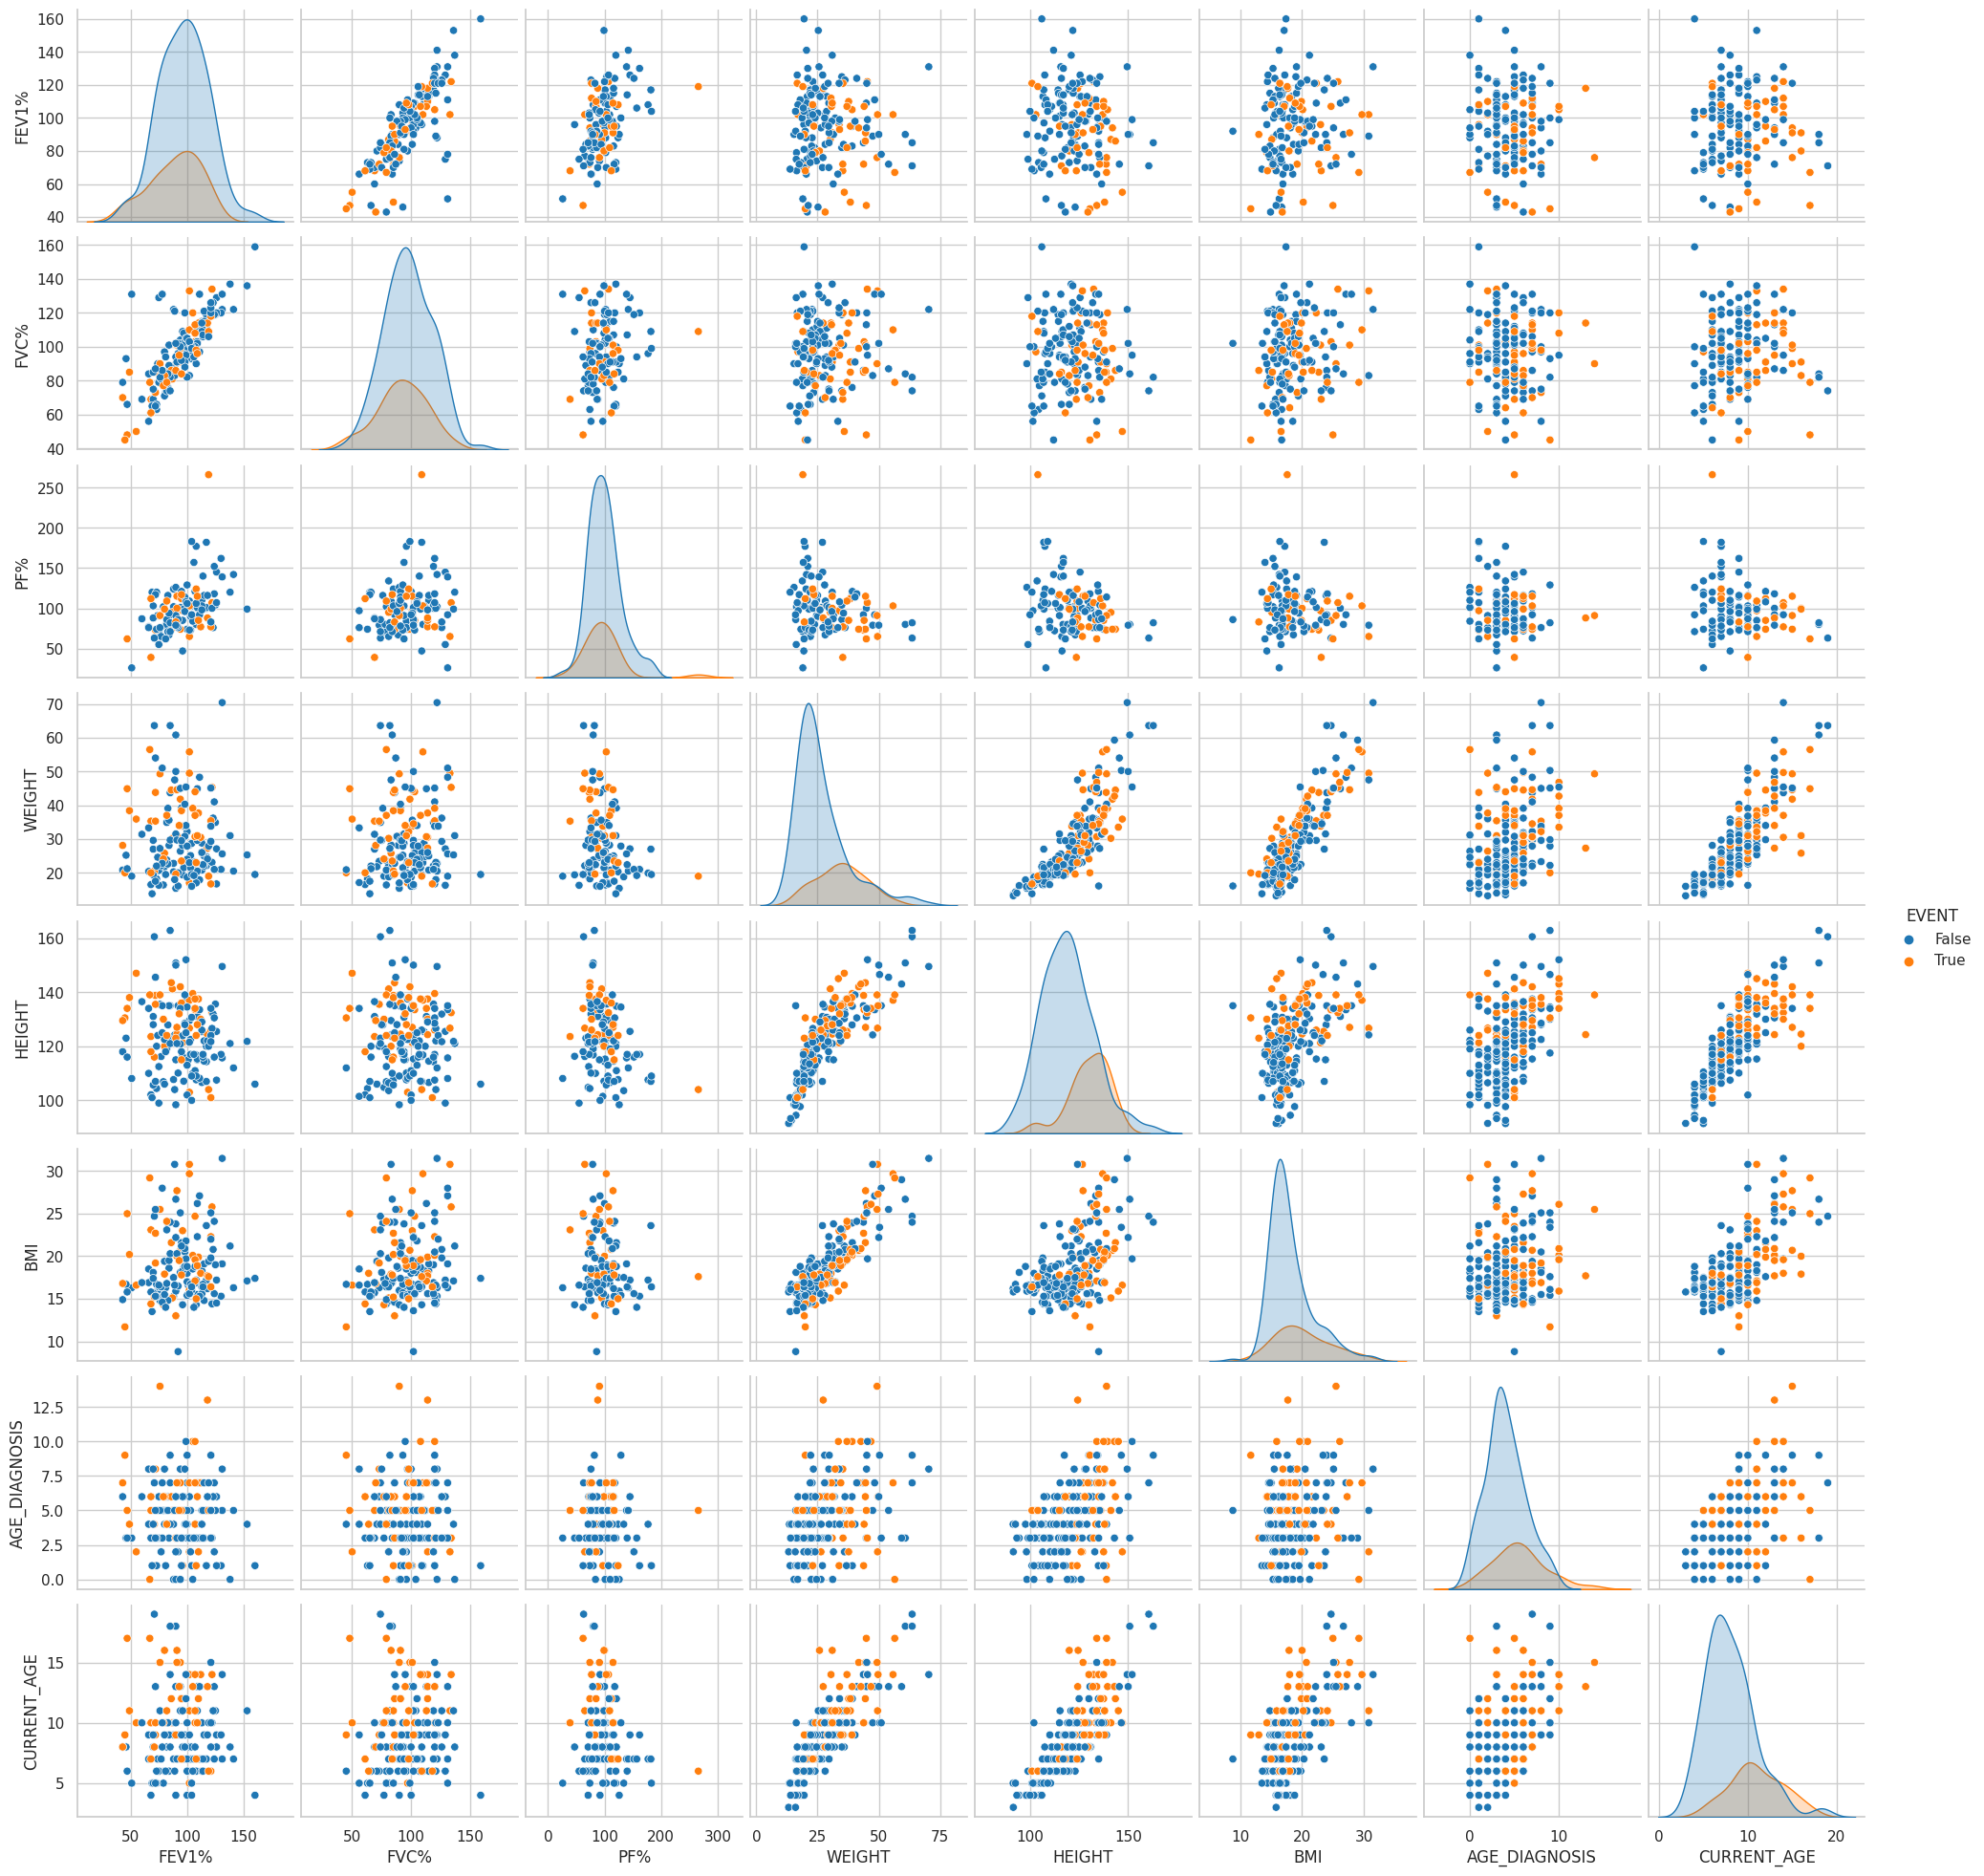

In [87]:
respi_var = ['FEV1%', 'FVC%', 'PF%', 'WEIGHT', 'HEIGHT', 'BMI', 'AGE_DIAGNOSIS', 'CURRENT_AGE', 'EVENT']
make_pairplots(df, respi_var)

### RESPI vs STEROID CM

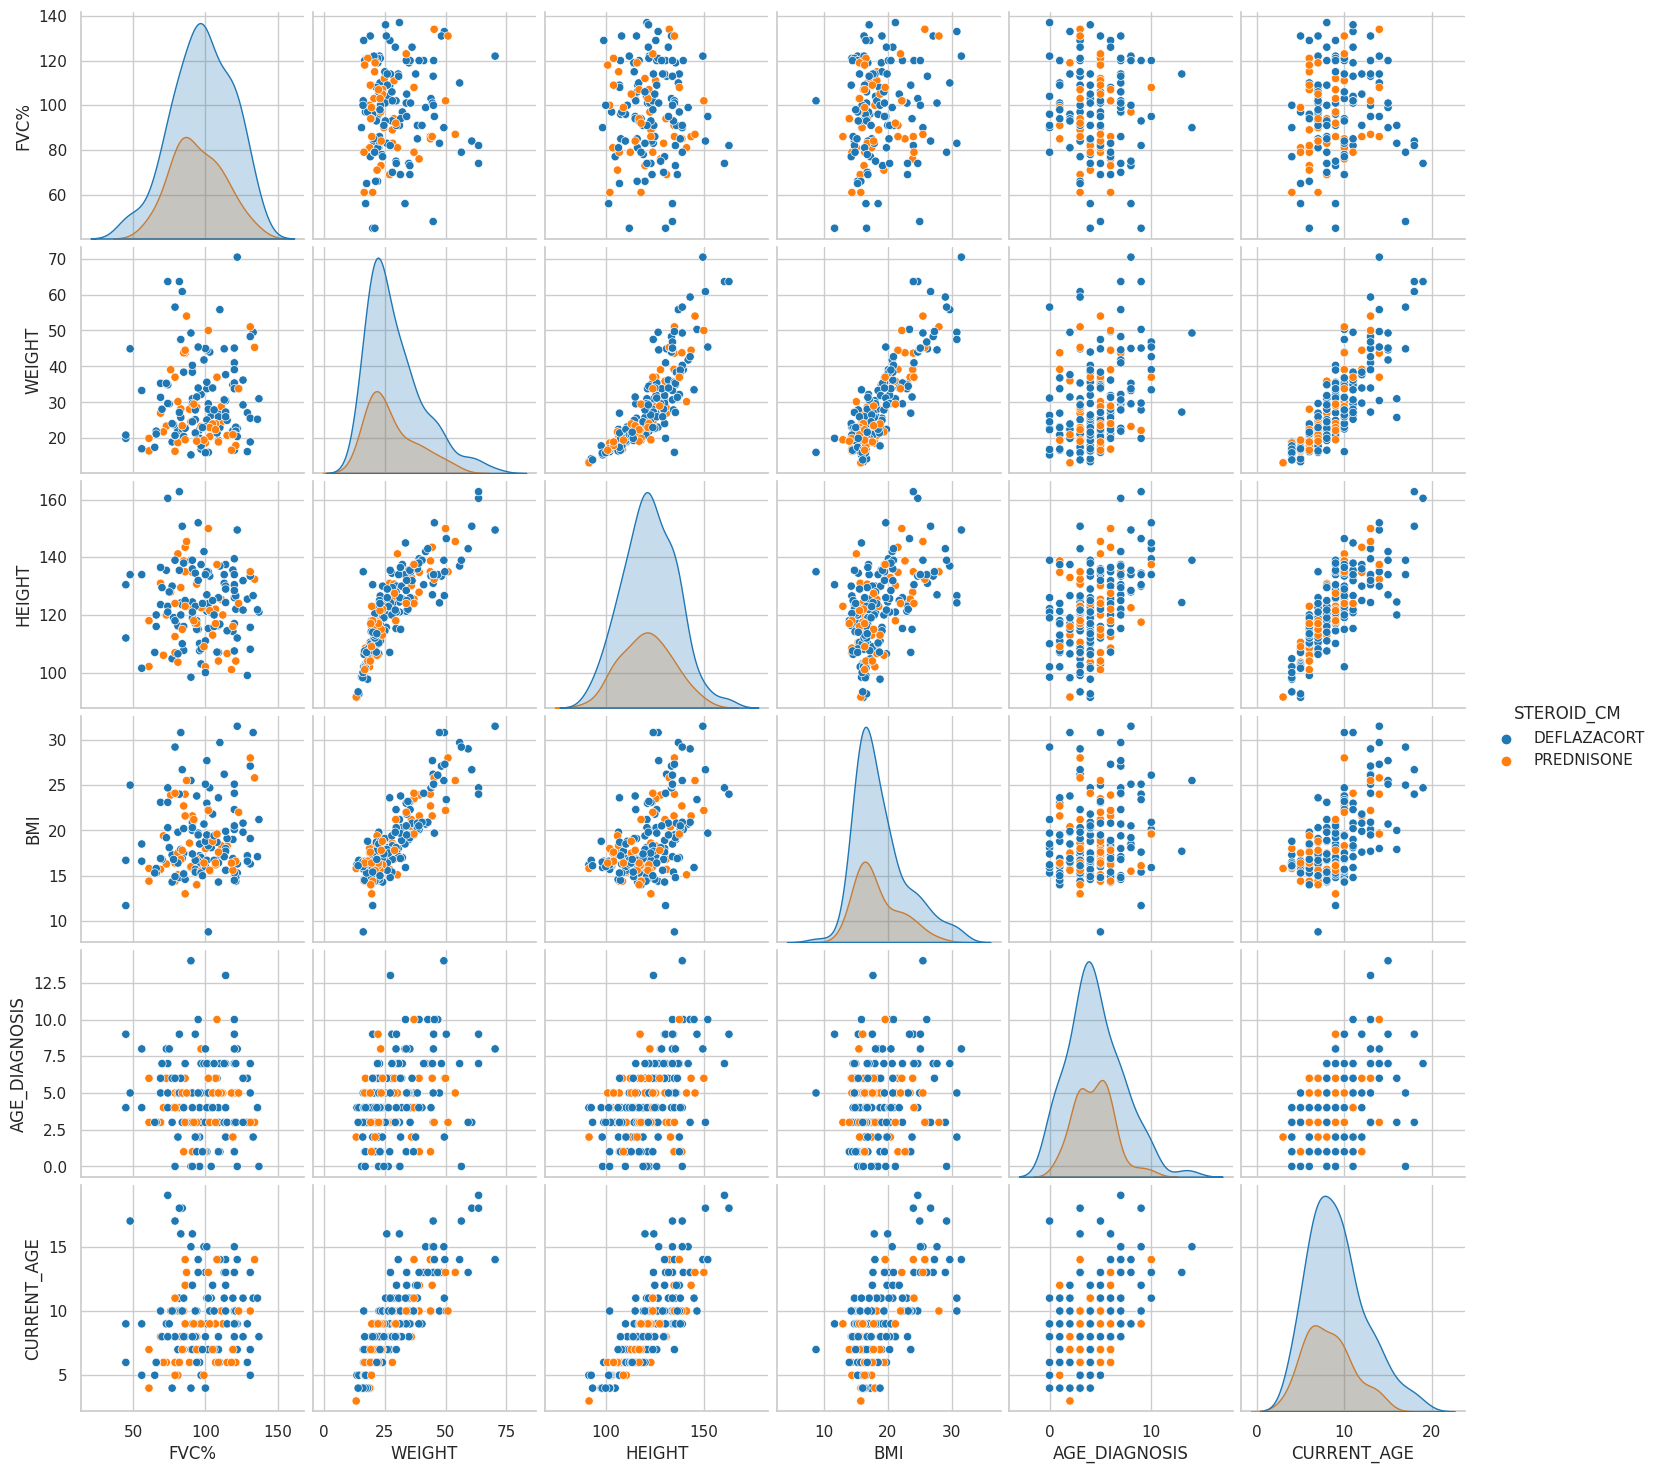

In [88]:
respi_var = ['FVC%', 'WEIGHT', 'HEIGHT', 'BMI', 'AGE_DIAGNOSIS', 'CURRENT_AGE', 'STEROID_CM']
make_pairplots(df, respi_var)

### RESPI vs MUTATION TYPE

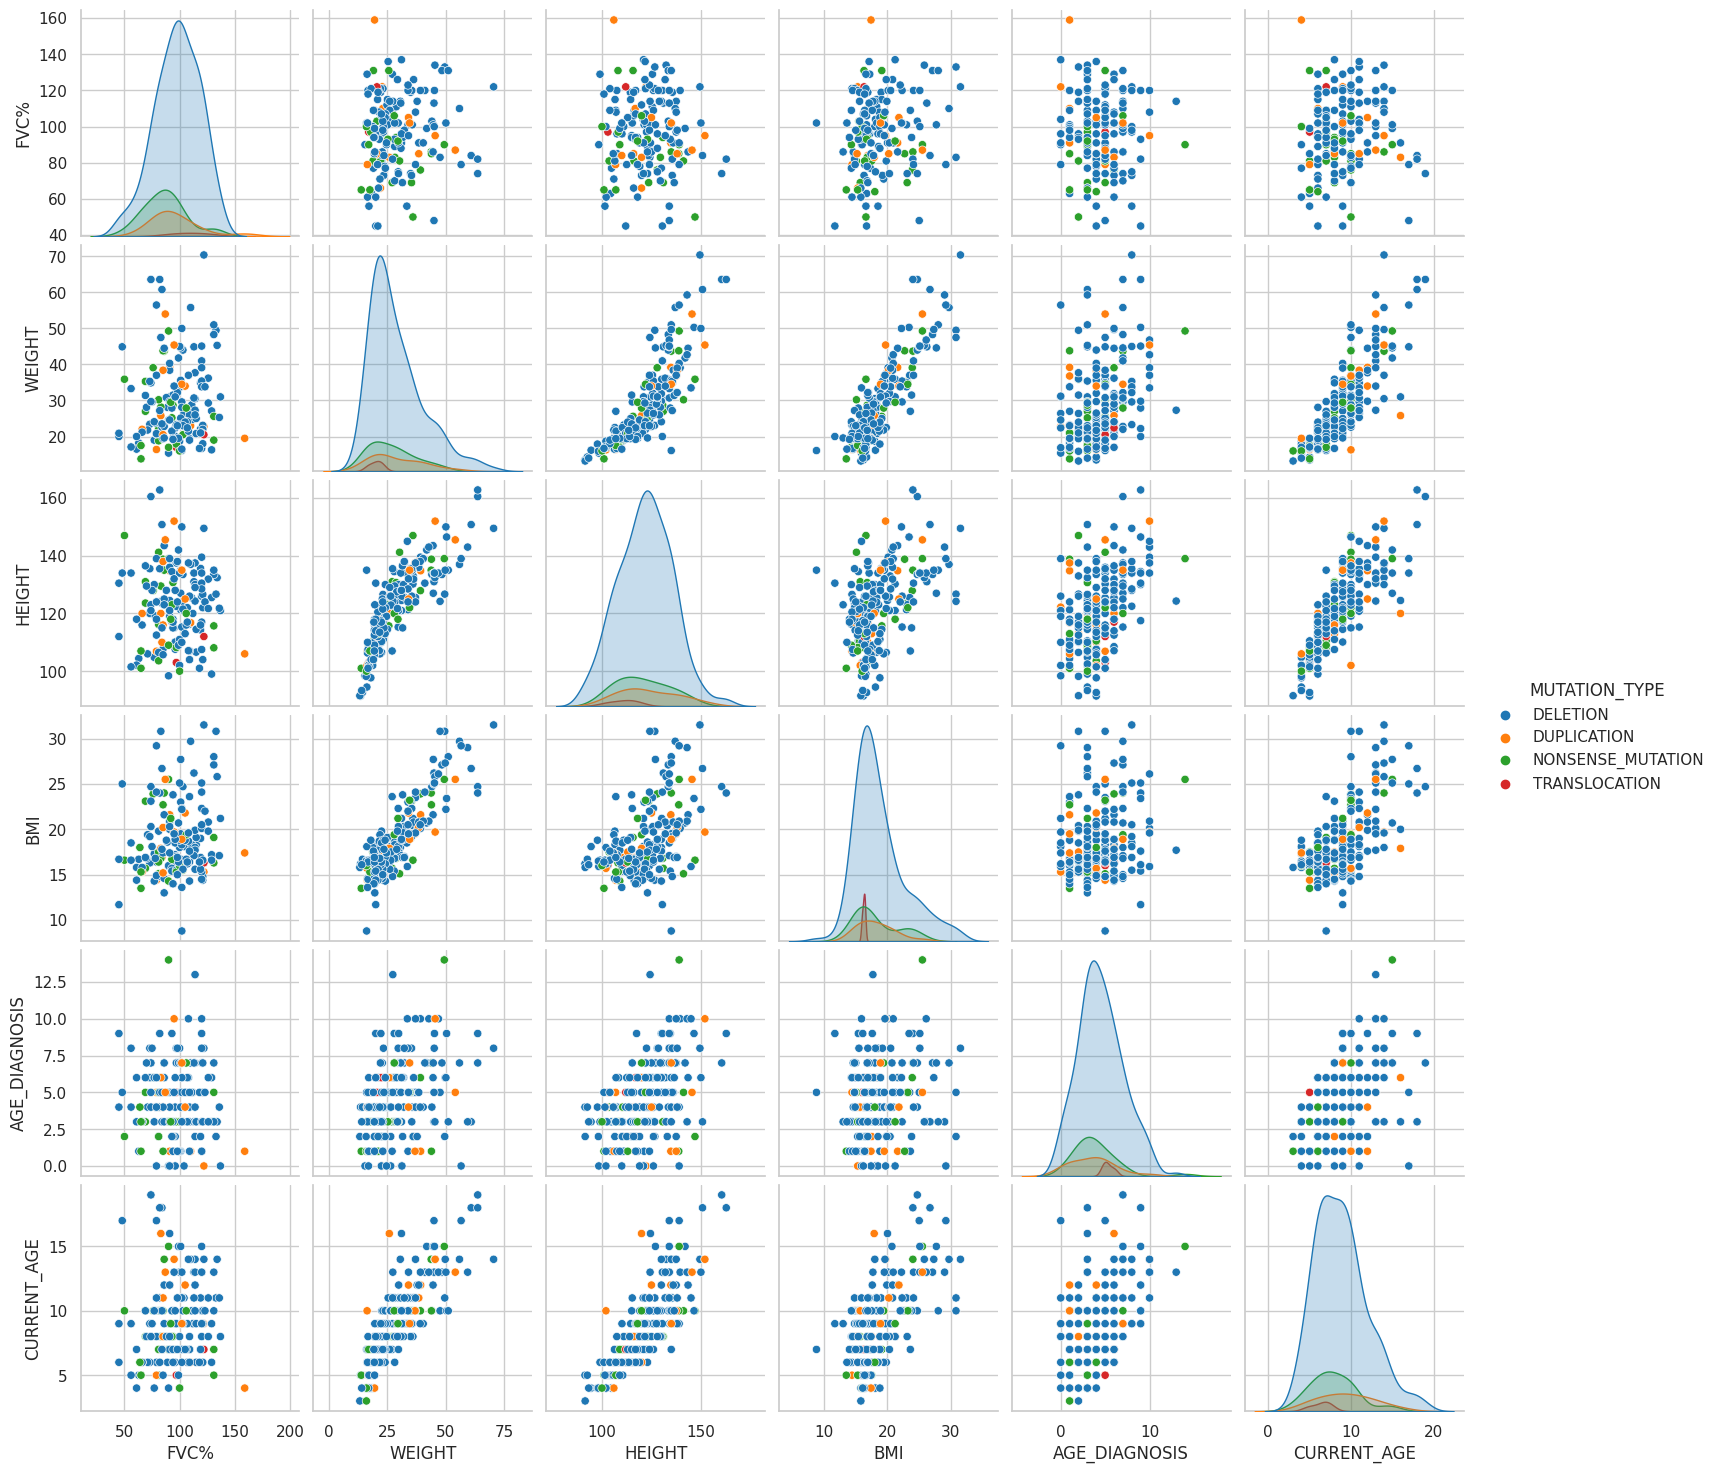

In [89]:
respi_var = ['FVC%', 'WEIGHT', 'HEIGHT', 'BMI', 'AGE_DIAGNOSIS', 'CURRENT_AGE', 'MUTATION_TYPE']
make_pairplots(df, respi_var)

### RESPI vs MUTATION LOCATION

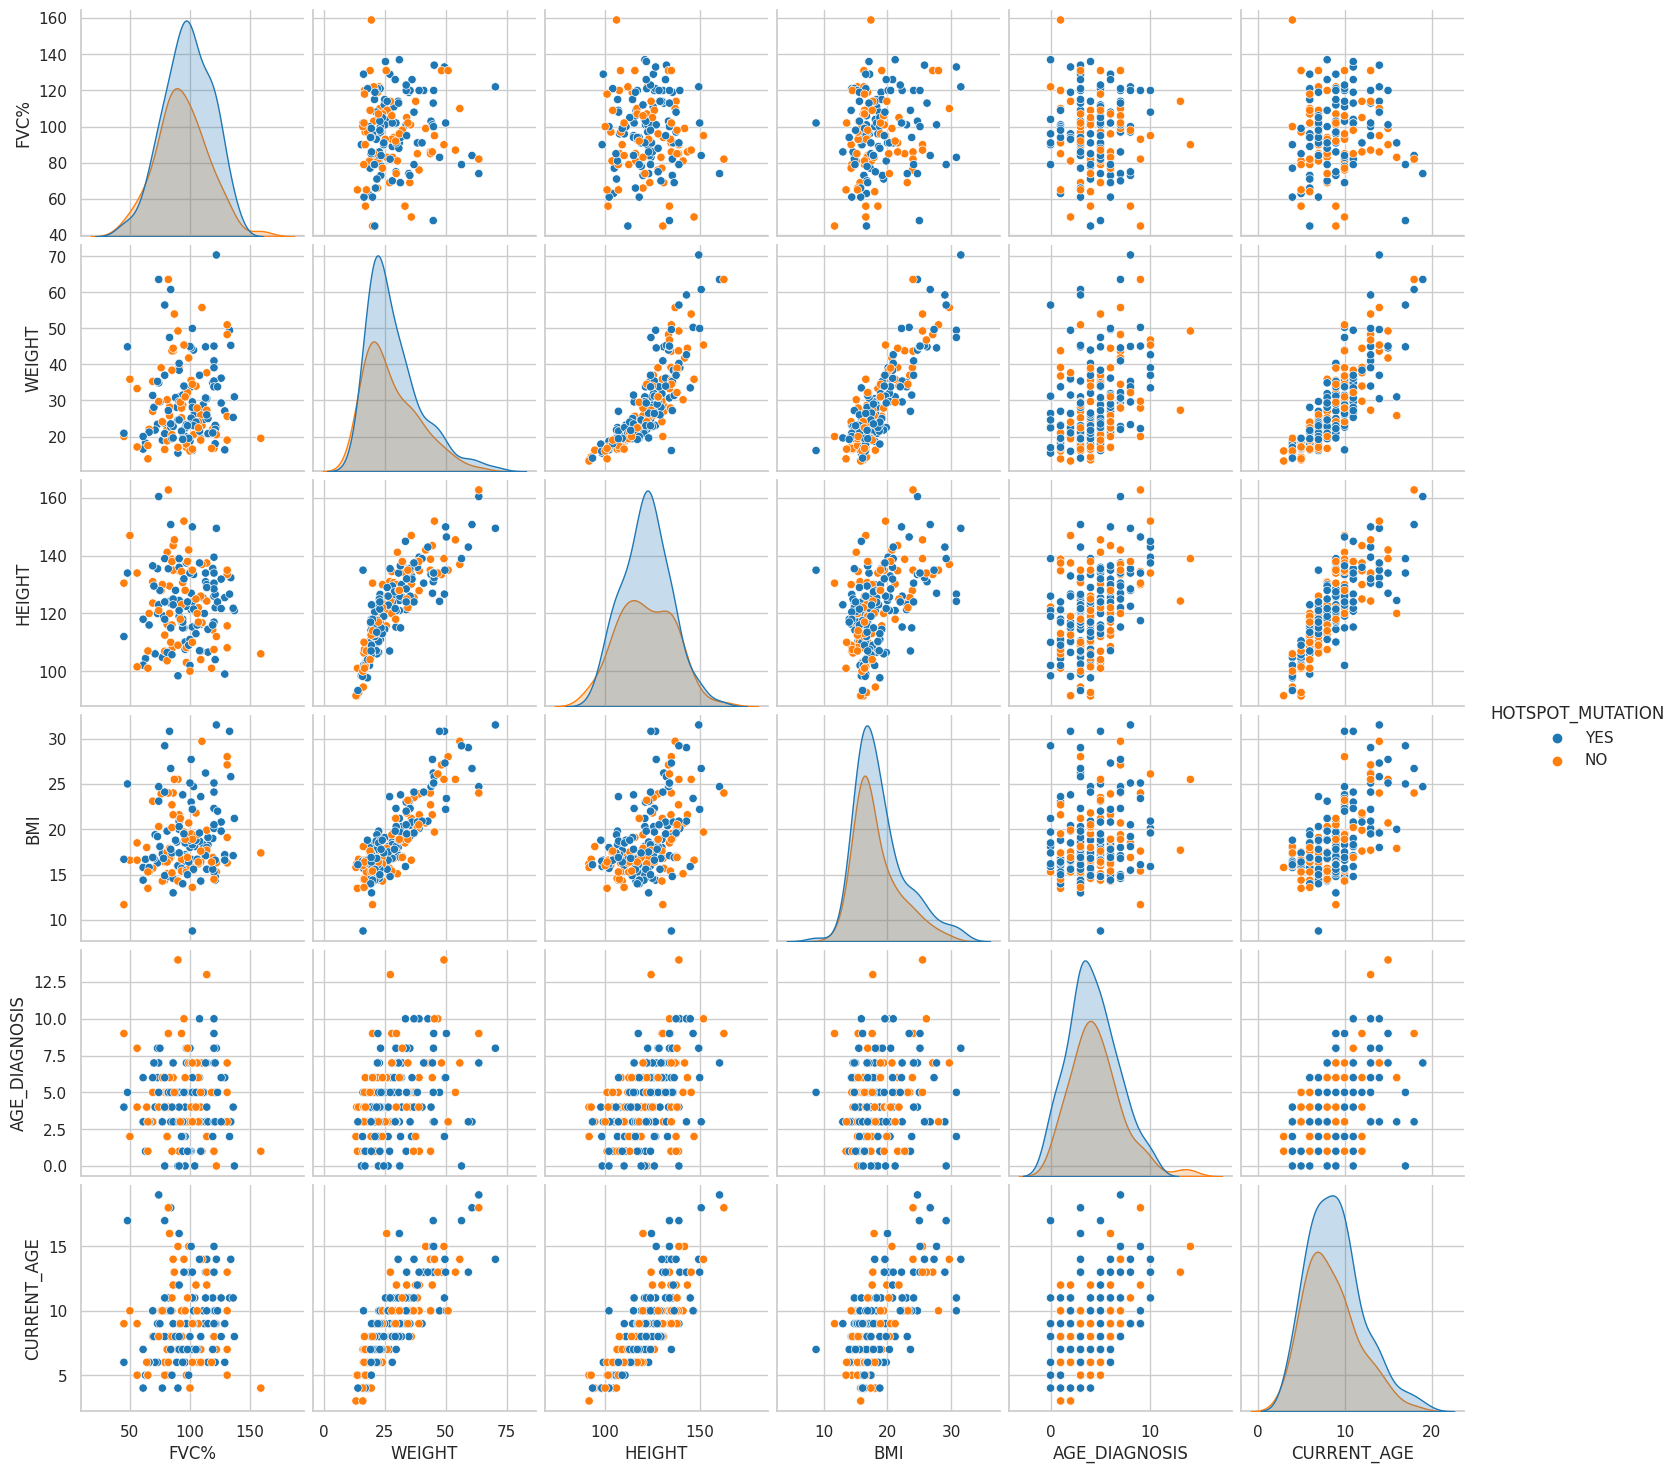

In [90]:
respi_var = ['FVC%', 'WEIGHT', 'HEIGHT', 'BMI', 'AGE_DIAGNOSIS', 'CURRENT_AGE', 'HOTSPOT_MUTATION']
make_pairplots(df, respi_var)

### Cardiovascular Measurements vs LoA

In [91]:
cv_vars = ['PR', 'QRS', 'QT', 'QTc', 'FRACTIONAL SHORTENING', 
           'LEFT POSTERIOR WALL THICKNESS', 'LEFT SEPTUM WALL THICKNESS', 'LV END DIASTOLIC DIAMETER', 'LVEF', 'LV END SYSTOLIC DIAMETER','EVENT']

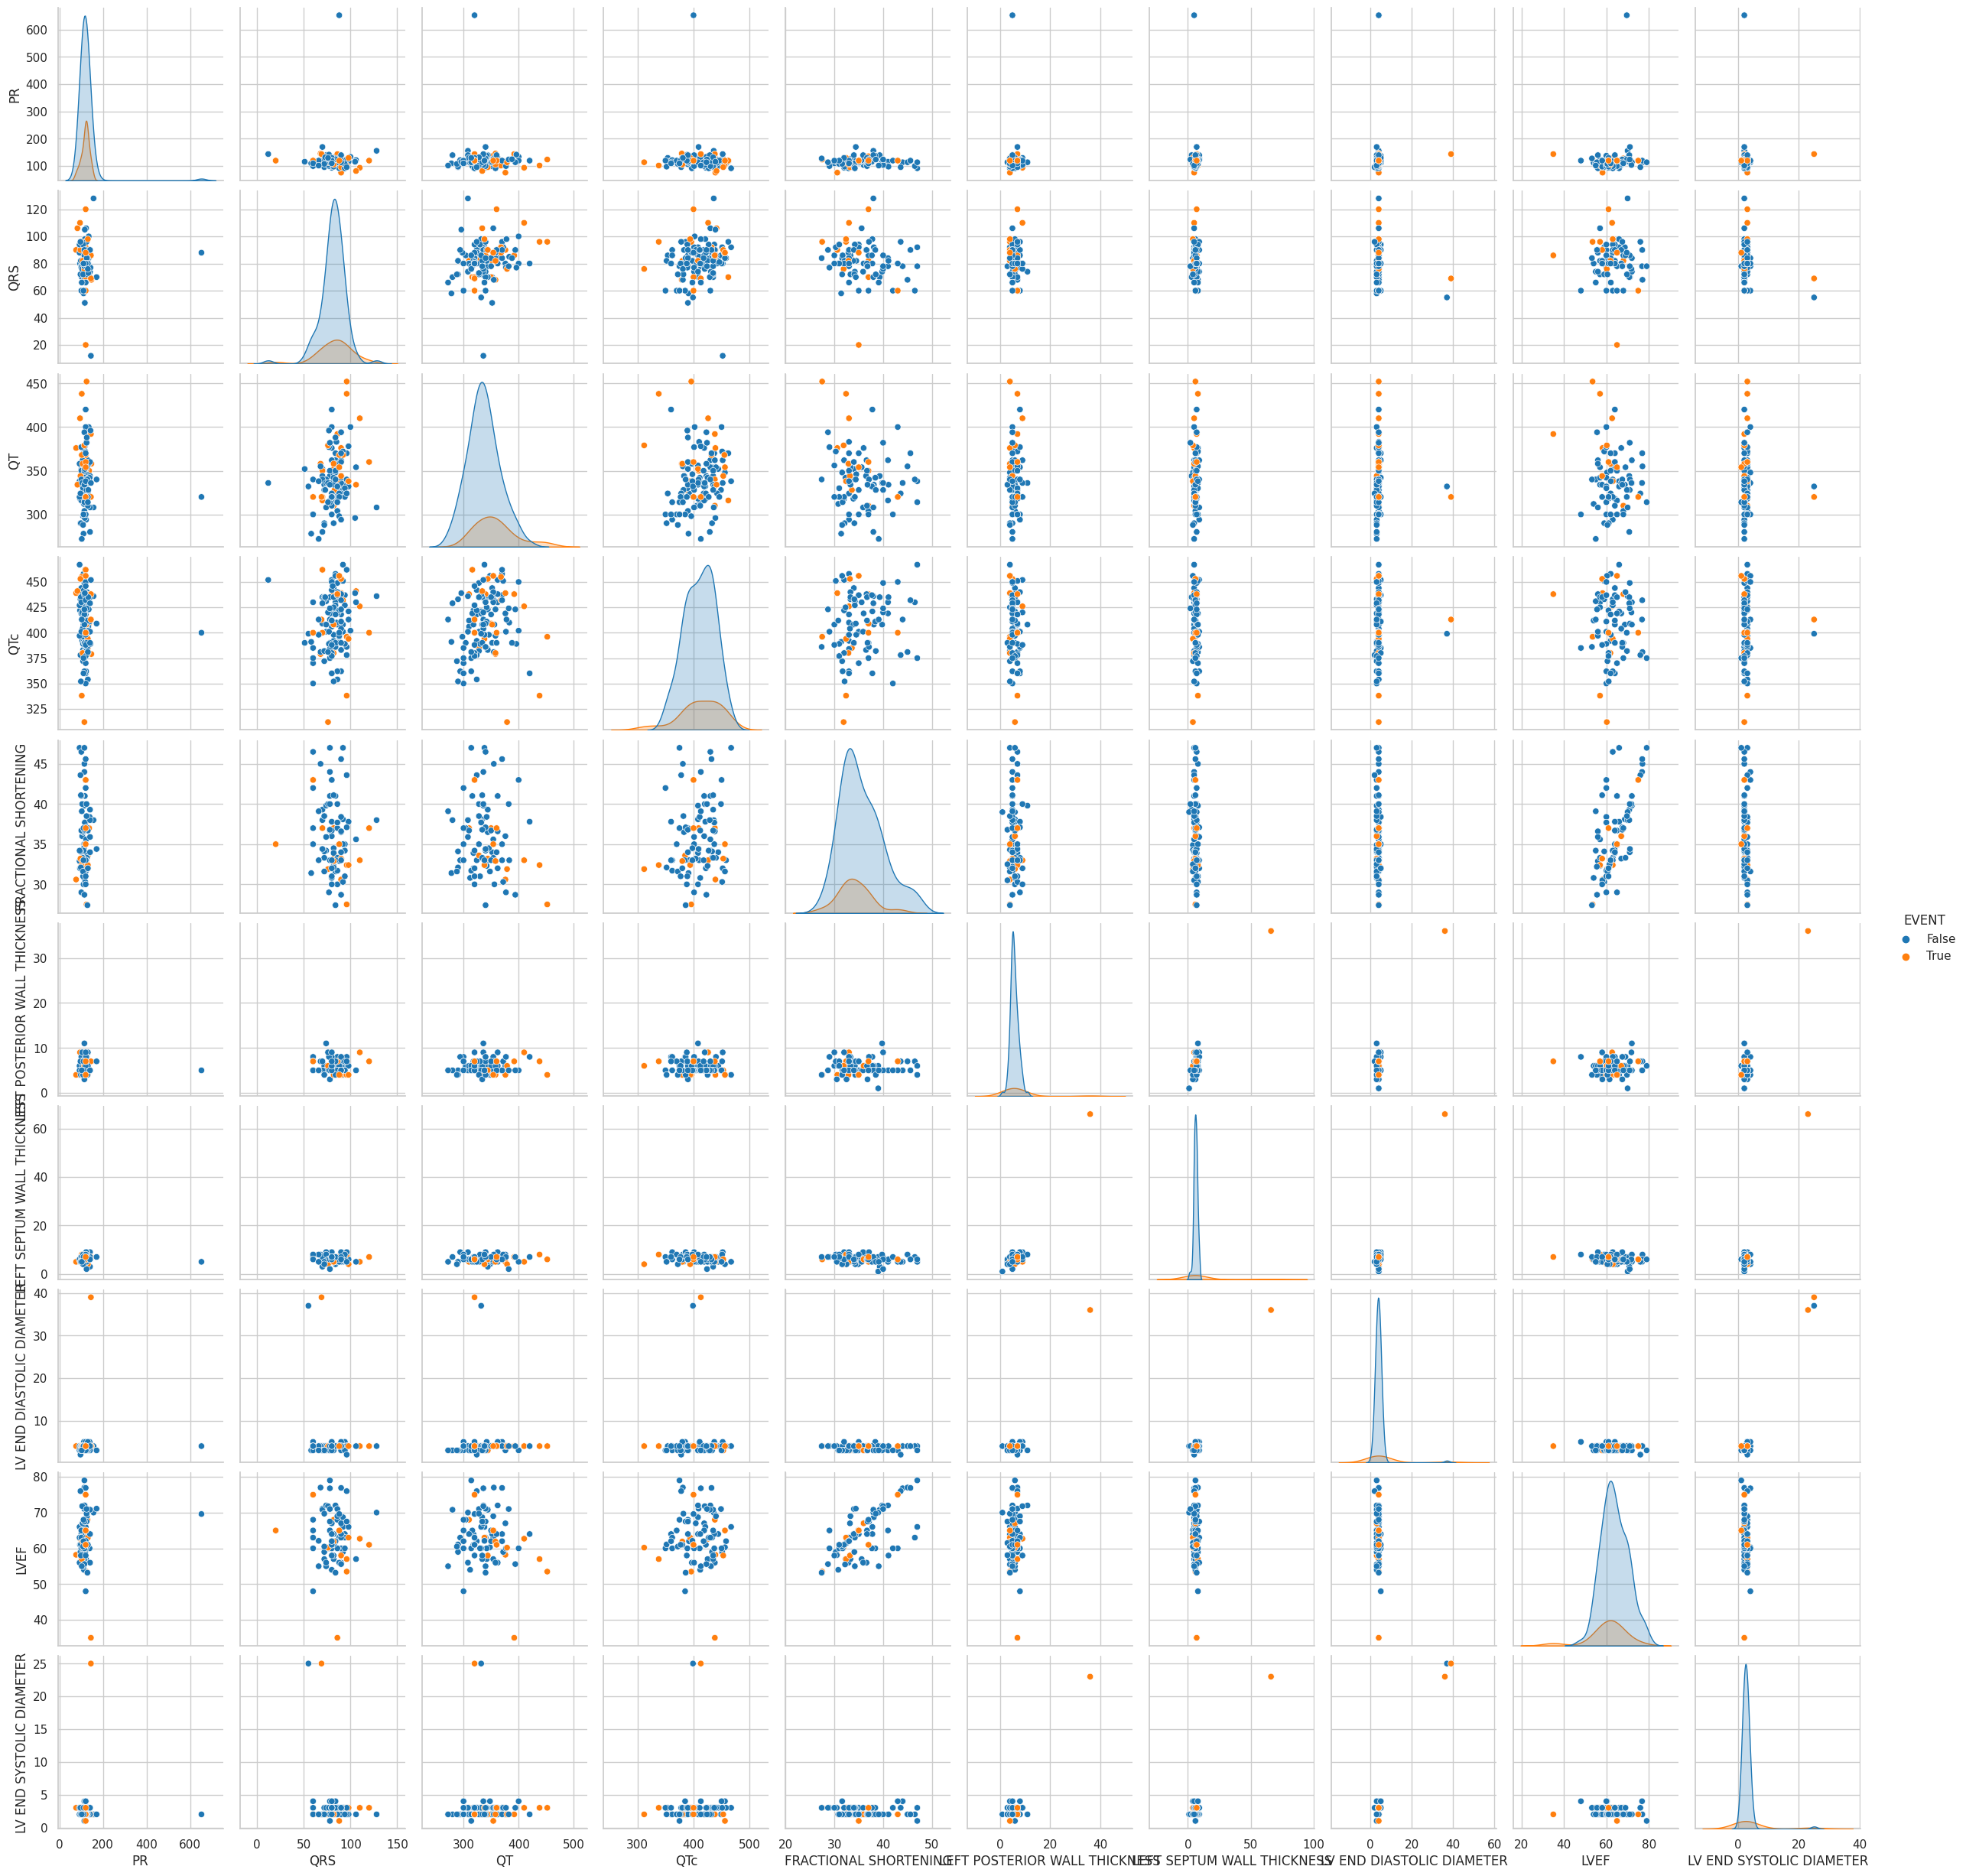

In [92]:
make_pairplots(df, cv_vars)

### Functional Measurements vs LoA

In [93]:
functional_vars = ['6MWD_DISWLK', '10MWALK', '4SCD_4-AGRAD', 'RISE_FROM_FLOOR', 'BMI', 'CURRENT_AGE', 'EVENT']

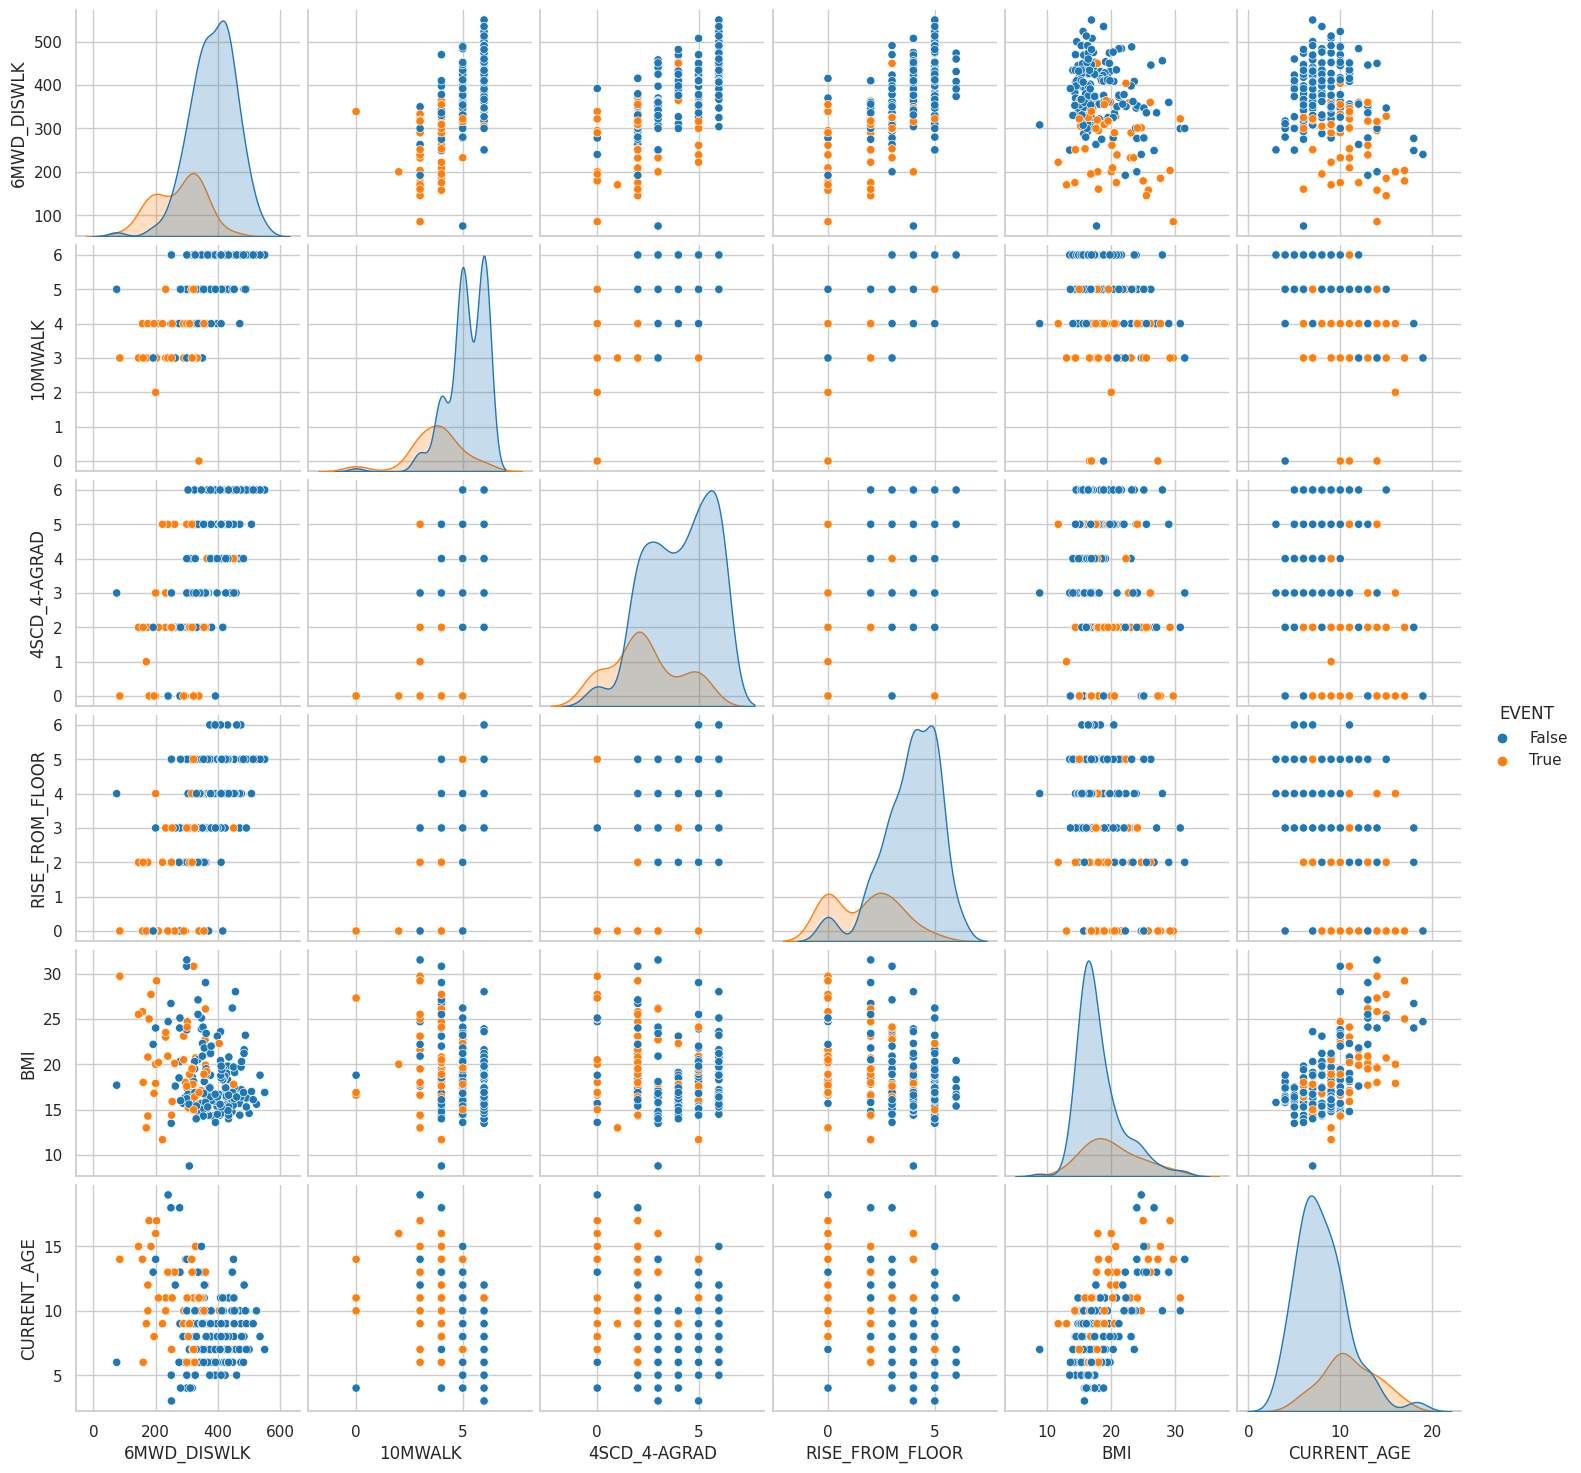

In [94]:
make_pairplots(df, functional_vars)

### NSAA

In [95]:
nsaa_var = ['NSAA', 'WEIGHT', 'HEIGHT', 'BMI', 'CURRENT_AGE', 'EVENT']

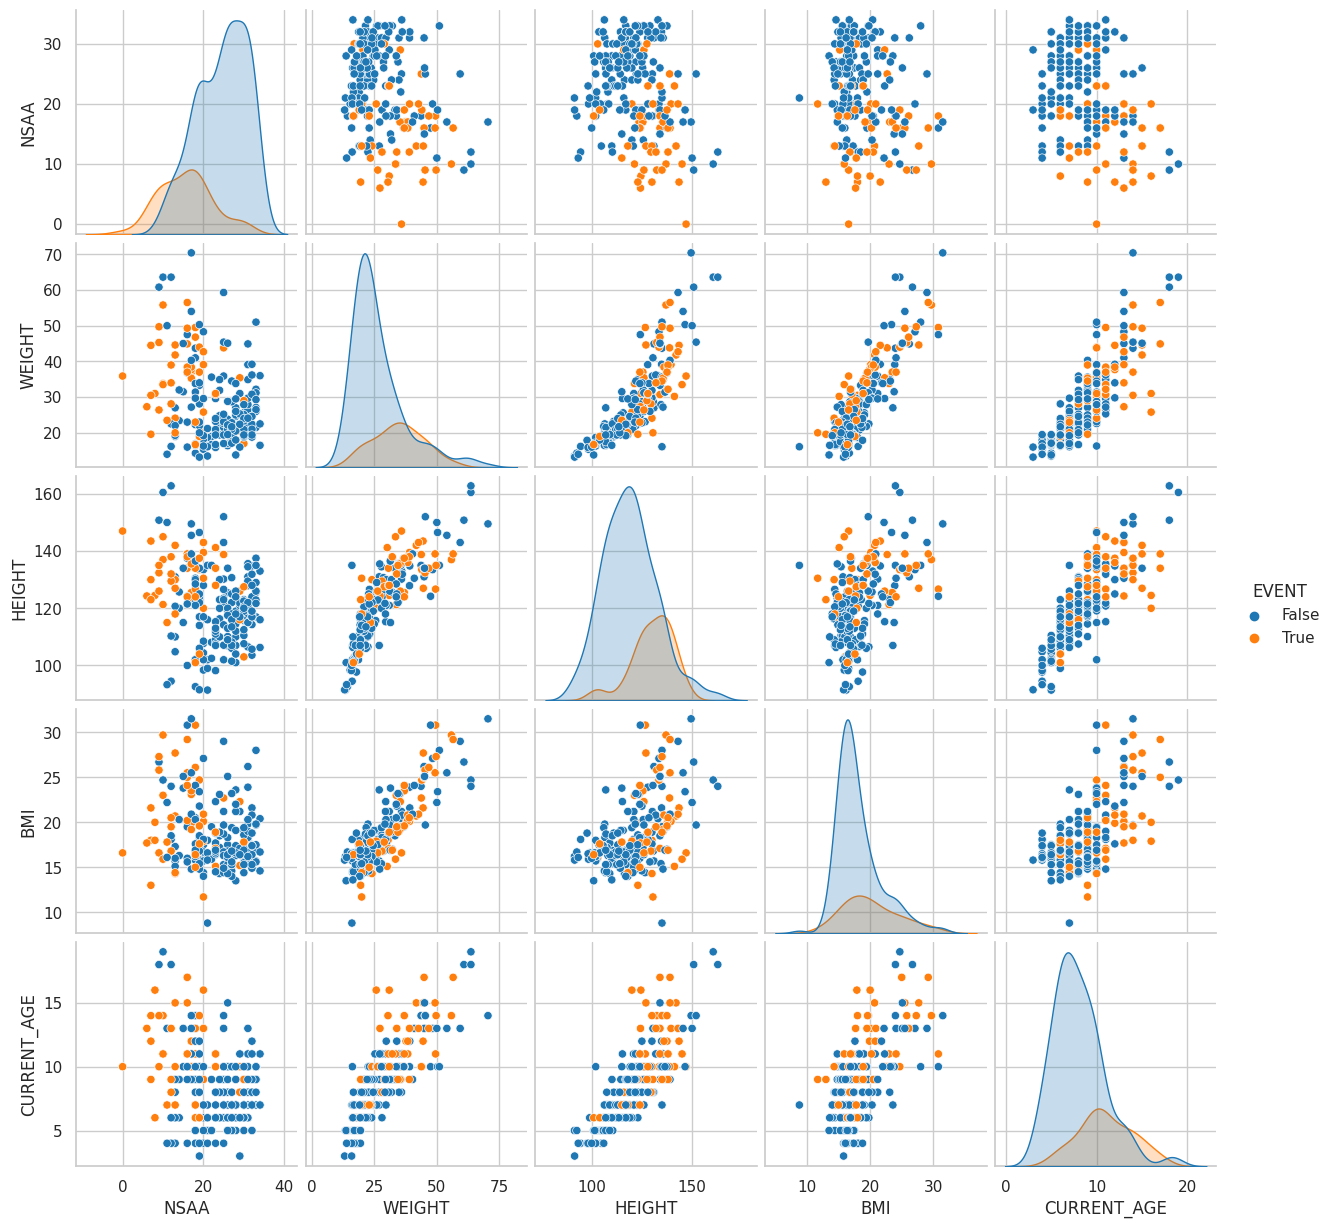

In [96]:
make_pairplots(df, nsaa_var)